## Results comparison for evaluation runs under spawn15 rule, and across the following sets of varying conditions:

#### -- TASK:
- Single class vs 
- multi-class environment
#### -- NAVIGATION:
- 4 naive policies vs 
- 1 AIF-inspired model
#### -- DETECTION MODEL:
- Ground-Truth deterministic detector based on FoV projection geometry vs 
- YOLO v11s trained on custom collected datasets (both bottles only and multiclass)
#### -- DETECTION SPEED CONSTRAINT:
- Full-speed, detection processing on every single frame
- Frame-constrained at 1 process every 10/20/50 frames
- Frame-constrained at 1 process every 0.1/0.5/1 seconds

In [1]:
from pathlib import Path
from glob import glob
import json
import math
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(
    context="talk",
    style="whitegrid",
    palette="deep",
    font_scale=1.05,
)

plt.rcParams.update({
    "figure.figsize": (14, 8),
    "figure.dpi": 120,
    "savefig.dpi": 250,
    "axes.titlesize": 22,
    "axes.labelsize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "legend.title_fontsize": 15,
    "axes.titlepad": 18,
})

In [2]:
# ---------------------------------------------------------------------
# EDIT THIS CELL ONLY WHEN YOU ADD / MOVE EXPERIMENT RESULT FILES
# ---------------------------------------------------------------------
#
# Each entry can point to:
# - a single eval_report.json file
# - a directory containing one or more eval_report.json files
# - a glob pattern, e.g. ".../eval_*/eval_report.json"
#
# The policy is intentionally NOT specified here.
# It is read directly from each eval_report.json file.

REPORT_SOURCES = [
    # -----------------------
    # Bottles-only dataset
    # -----------------------
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_aif_saccade_FAKER_spawn15_YOLO/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_aif_saccade_FAKER_spawn15_GT/eval_report/eval_report.json",
    },
    
        {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_pseudo_random_spawn15_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_pseudo_random_spawn15_YOLO/eval_report/eval_report.json",
    },

        {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_rotate_and_measure_spawn15_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_rotate_and_measure_spawn15_YOLO/eval_report/eval_report.json",
    },

        {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_spiral_spawn15_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_spiral_spawn15_YOLO/eval_report/eval_report.json",
    },

            {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_wall_following_spawn15_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_wall_following_spawn15_YOLO/eval_report/eval_report.json",
    },

    # -----------------------
    # Mixed / multiclass dataset
    # -----------------------
    {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_aif_saccade_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_aif_saccade_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },

        {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_pseudo_random_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_pseudo_random_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },

        {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_spiral_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_spiral_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },

        {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_wall_following_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_wall_following_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },

        {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_rotate_and_measure_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_rotate_and_measure_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },
]

POLICY_ORDER = [
    "aif_saccade",
    "pseudo_random",
    "wall_following",
    "spiral",
    "rotate_and_measure",
]

POLICY_LABELS = {
    "aif_saccade": "AIF Saccade",
    "pseudo_random": "Pseudo Random",
    "wall_following": "Wall Following",
    "spiral": "Spiral",
    "rotate_and_measure": "Rotate and Measure",
}

DETECTOR_ORDER = ["GT", "YOLO"]
DATASET_ORDER = ["Bottles only", "Mixed"]

SAVE_FIGURES = True
FIGURE_DIR = Path("figures_eval_comparison")
FIGURE_DIR.mkdir(exist_ok=True)

In [3]:
def expand_report_paths(path_like):
    """
    Accepts a file, directory, or glob pattern.
    Returns a sorted list of eval_report.json paths.
    """
    path_str = str(path_like)
    p = Path(path_str)

    if any(ch in path_str for ch in ["*", "?", "["]):
        paths = [Path(x) for x in glob(path_str, recursive=True)]
    elif p.is_dir():
        paths = list(p.rglob("eval_report.json"))
    elif p.is_file():
        paths = [p]
    else:
        paths = []

    return sorted(set(path.resolve() for path in paths if path.name.endswith(".json")))


def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


def normalize_policy_name(policy):
    """
    Normalizes policy names so small naming variations still group together.
    The value is still read from the JSON report, not from REPORT_SOURCES.
    """
    if policy is None or pd.isna(policy):
        return "unknown_policy"

    p = str(policy).strip().lower()
    p = p.replace("-", "_").replace(" ", "_")

    aliases = {
        "aif": "aif_saccade",
        "aif_saccade": "aif_saccade",
        "saccade": "aif_saccade",

        "pseudo_random": "pseudo_random",
        "pseudorandom": "pseudo_random",
        "random": "pseudo_random",

        "wall_following": "wall_following",
        "wallfollowing": "wall_following",

        "rotate_and_measure": "rotate_and_measure",
        "rotate_measure": "rotate_and_measure",
        "rotateandmeasure": "rotate_and_measure",
        "rotate_measure_policy": "rotate_and_measure",

        "spiral": "spiral",
    }

    return aliases.get(p, p)


def pretty_policy_name(policy):
    """
    Converts machine names into readable labels without changing grouping.
    Uses POLICY_LABELS from the config cell when available.
    """
    if policy is None or pd.isna(policy):
        return "Unknown"

    policy = normalize_policy_name(policy)

    if "POLICY_LABELS" in globals() and policy in POLICY_LABELS:
        return POLICY_LABELS[policy]

    replacements = {
        "aif_saccade": "AIF Saccade",
        "pseudo_random": "Pseudo Random",
        "wall_following": "Wall Following",
        "rotate_and_measure": "Rotate and Measure",
        "spiral": "Spiral",
    }

    return replacements.get(policy, policy.replace("_", " ").title())


def infer_success(run):
    """
    Robust run-level success inference.
    Prefer explicit remaining_objects when available.
    Otherwise use reason == 'done'.
    """
    if "remaining_objects" in run and run["remaining_objects"] is not None:
        return float(run["remaining_objects"] == 0)

    reason = str(run.get("reason", "")).lower()
    if reason:
        return float(reason in {"done", "success", "completed", "complete"})

    return np.nan


def _clean_optional_number(value):
    """
    Converts missing / None / NaN / stringified None into None.
    Otherwise returns the numeric/string value unchanged.
    """
    if value is None:
        return None

    if isinstance(value, float) and np.isnan(value):
        return None

    if isinstance(value, str) and value.strip().lower() in {"", "none", "null", "nan"}:
        return None

    return value


def infer_yolo_condition(report, detector):
    """
    Infers the detector-processing condition from report-level entries.

    Expected possibilities:
    - frame_cap: 20
    - frame_cap_sec: 0.5
    - both absent or None -> unlimited YOLO

    If both are present and non-null, this raises an error because the report
    would be ambiguous.
    """
    detector = str(detector)

    if detector.upper() == "GT":
        return {
            "condition_label": "GT",
            "condition_type": "gt",
            "condition_value": np.nan,
            "frame_cap": np.nan,
            "frame_cap_sec": np.nan,
        }

    frame_cap = _clean_optional_number(report.get("frame_cap", None))
    frame_cap_sec = _clean_optional_number(report.get("frame_cap_sec", None))

    if frame_cap is not None and frame_cap_sec is not None:
        raise ValueError(
            "Ambiguous YOLO cap condition: both frame_cap and frame_cap_sec "
            f"are non-null in report for policy={report.get('policy')!r}."
        )

    if frame_cap is not None:
        return {
            "condition_label": f"YOLO capped at {frame_cap:g} frames" if isinstance(frame_cap, (int, float)) else f"YOLO capped at {frame_cap} frames",
            "condition_type": "frame_cap",
            "condition_value": float(frame_cap),
            "frame_cap": float(frame_cap),
            "frame_cap_sec": np.nan,
        }

    if frame_cap_sec is not None:
        return {
            "condition_label": f"YOLO capped at {frame_cap_sec:g} s" if isinstance(frame_cap_sec, (int, float)) else f"YOLO capped at {frame_cap_sec} s",
            "condition_type": "frame_cap_sec",
            "condition_value": float(frame_cap_sec),
            "frame_cap": np.nan,
            "frame_cap_sec": float(frame_cap_sec),
        }

    return {
        "condition_label": "YOLO unlimited",
        "condition_type": "unlimited_yolo",
        "condition_value": np.nan,
        "frame_cap": np.nan,
        "frame_cap_sec": np.nan,
    }


def flatten_eval_report(report, *, path, dataset, detector):
    """
    Converts one eval_report.json into one row per run.

    Policy is read from the JSON itself:
    - first from top-level report["policy"]
    - then from each run["policy"] if needed

    YOLO cap condition is inferred from report-level:
    - frame_cap
    - frame_cap_sec
    """
    runs = report.get("runs", [])
    cap_info = infer_yolo_condition(report, detector)

    rows = []
    for run in runs:
        raw_policy = report.get("policy") or run.get("policy") or "unknown_policy"
        policy = normalize_policy_name(raw_policy)

        classification = run.get("classification", {}) or {}

        found = run.get("found_count", np.nan)
        remaining = run.get("remaining_objects", np.nan)

        total_objects = np.nan
        if pd.notna(found) and pd.notna(remaining):
            total_objects = found + remaining

        detected_objects_ratio = (
            found / total_objects
            if pd.notna(found) and pd.notna(total_objects) and total_objects > 0
            else np.nan
        )

        row = {
            "dataset": dataset,
            "detector": detector,
            "condition_label": cap_info["condition_label"],
            "condition_type": cap_info["condition_type"],
            "condition_value": cap_info["condition_value"],
            "frame_cap": cap_info["frame_cap"],
            "frame_cap_sec": cap_info["frame_cap_sec"],

            "policy": policy,
            "policy_label": pretty_policy_name(policy),
            "source_path": str(path),

            "run_index": run.get("run_index", np.nan),
            "seed": run.get("seed", np.nan),
            "reason": run.get("reason", None),

            "elapsed_s": run.get("elapsed_s", np.nan),
            "found_count": found,
            "remaining_objects": remaining,
            "total_objects": total_objects,
            "detected_objects_ratio": detected_objects_ratio,
            "coverage_ratio": run.get("coverage_ratio", np.nan),
            "success": infer_success(run),

            "unique_claims_evaluated": classification.get("unique_claims_evaluated", np.nan),
            "correct_class_claims": classification.get("correct_class_claims", np.nan),
            "wrong_class_claims": classification.get("wrong_class_claims", np.nan),
            "empty_cell_claims": classification.get("empty_cell_claims", np.nan),
            "duplicate_claims_ignored": classification.get("duplicate_claims_ignored", np.nan),
            "object_cell_claims": classification.get("object_cell_claims", np.nan),
            "object_cell_class_accuracy": classification.get("object_cell_class_accuracy", np.nan),
            "overall_claim_precision": classification.get("overall_claim_precision", np.nan),

            "confusion_matrix": classification.get("confusion_matrix", None),
        }

        rows.append(row)

    return pd.DataFrame(rows)


def make_order(values, preferred_order):
    """
    Keeps preferred order first, then appends any unseen values alphabetically.
    """
    values = [v for v in pd.Series(values).dropna().unique().tolist()]
    preferred_present = [v for v in preferred_order if v in values]
    extras = sorted([v for v in values if v not in preferred_present])
    return preferred_present + extras


def make_condition_order(df):
    """
    Makes a readable and stable order for GT / unlimited YOLO / capped YOLO variants.
    """
    if "condition_label" not in df.columns:
        return []

    gt = ["GT"] if "GT" in set(df["condition_label"].dropna()) else []
    unlimited = ["YOLO unlimited"] if "YOLO unlimited" in set(df["condition_label"].dropna()) else []

    sec_caps = (
        df[df["condition_type"] == "frame_cap_sec"]
        [["condition_label", "condition_value"]]
        .drop_duplicates()
        .sort_values("condition_value")
        ["condition_label"]
        .tolist()
    )

    frame_caps = (
        df[df["condition_type"] == "frame_cap"]
        [["condition_label", "condition_value"]]
        .drop_duplicates()
        .sort_values("condition_value")
        ["condition_label"]
        .tolist()
    )

    all_ordered = gt + unlimited + sec_caps + frame_caps
    extras = sorted([x for x in df["condition_label"].dropna().unique() if x not in all_ordered])

    return all_ordered + extras

In [4]:
all_run_frames = []
load_log = []

for src in REPORT_SOURCES:
    dataset = src["dataset"]
    detector = src["detector"]
    paths = expand_report_paths(src["path"])

    load_log.append({
        "dataset": dataset,
        "detector": detector,
        "configured_path": src["path"],
        "num_files_found": len(paths),
    })

    for path in paths:
        report = load_json(path)
        df_one = flatten_eval_report(
            report,
            path=path,
            dataset=dataset,
            detector=detector,
        )
        all_run_frames.append(df_one)

load_log_df = pd.DataFrame(load_log)
display(Markdown("### Load log"))
display(load_log_df)

if not all_run_frames:
    raise FileNotFoundError(
        "No eval_report.json files were found. "
        "Edit REPORT_SOURCES so each path points to a file, directory, or glob."
    )

runs_df = pd.concat(all_run_frames, ignore_index=True)

policy_order = make_order(runs_df["policy"].unique(), POLICY_ORDER)
detector_order = make_order(runs_df["detector"].unique(), DETECTOR_ORDER)
dataset_order = make_order(runs_df["dataset"].unique(), DATASET_ORDER)
condition_order = make_condition_order(runs_df)

runs_df["policy"] = pd.Categorical(runs_df["policy"], categories=policy_order, ordered=True)
runs_df["policy_label"] = pd.Categorical(
    runs_df["policy_label"],
    categories=[pretty_policy_name(p) for p in policy_order],
    ordered=True,
)
runs_df["detector"] = pd.Categorical(runs_df["detector"], categories=detector_order, ordered=True)
runs_df["dataset"] = pd.Categorical(runs_df["dataset"], categories=dataset_order, ordered=True)
runs_df["condition_label"] = pd.Categorical(
    runs_df["condition_label"],
    categories=condition_order,
    ordered=True,
)

display(Markdown("### Loaded run-level dataframe"))
display(runs_df.head())

display(Markdown("### Runs per dataset / detector / condition / policy"))
display(
    runs_df
    .groupby(["dataset", "detector", "condition_label", "policy_label"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
)

display(Markdown("### Detected YOLO cap conditions"))
display(
    runs_df
    .groupby(["dataset", "detector", "condition_label", "condition_type", "condition_value"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
)

### Load log

,dataset,detector,configured_path,num_files_found
0,Bottles only,YOLO,../logs_bottles_only/eval_aif_saccade_FAKER_sp...,1
1,Bottles only,GT,../logs_bottles_only/eval_aif_saccade_FAKER_sp...,1
2,Bottles only,GT,../logs_bottles_only/eval_pseudo_random_spawn1...,1
3,Bottles only,YOLO,../logs_bottles_only/eval_pseudo_random_spawn1...,1
4,Bottles only,GT,../logs_bottles_only/eval_rotate_and_measure_s...,1
5,Bottles only,YOLO,../logs_bottles_only/eval_rotate_and_measure_s...,1
6,Bottles only,GT,../logs_bottles_only/eval_spiral_spawn15_GT/ev...,1
7,Bottles only,YOLO,../logs_bottles_only/eval_spiral_spawn15_YOLO/...,1
8,Bottles only,GT,../logs_bottles_only/eval_wall_following_spawn...,1
9,Bottles only,YOLO,../logs_bottles_only/eval_wall_following_spawn...,1


### Loaded run-level dataframe

,dataset,detector,condition_label,condition_type,condition_value,frame_cap,frame_cap_sec,policy,policy_label,source_path,...,success,unique_claims_evaluated,correct_class_claims,wrong_class_claims,empty_cell_claims,duplicate_claims_ignored,object_cell_claims,object_cell_class_accuracy,overall_claim_precision,confusion_matrix
0,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,NaN,NaN,aif_saccade,AIF Saccade,/home/ale/dev/thesis_project/aif-explo-drones/...,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
1,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,NaN,NaN,aif_saccade,AIF Saccade,/home/ale/dev/thesis_project/aif-explo-drones/...,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,NaN,NaN,aif_saccade,AIF Saccade,/home/ale/dev/thesis_project/aif-explo-drones/...,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,NaN,NaN,aif_saccade,AIF Saccade,/home/ale/dev/thesis_project/aif-explo-drones/...,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
4,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,NaN,NaN,aif_saccade,AIF Saccade,/home/ale/dev/thesis_project/aif-explo-drones/...,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


### Runs per dataset / detector / condition / policy

,dataset,detector,condition_label,policy_label,num_runs
0,Bottles only,GT,GT,AIF Saccade,10
1,Bottles only,GT,GT,Pseudo Random,10
2,Bottles only,GT,GT,Wall Following,10
3,Bottles only,GT,GT,Spiral,10
4,Bottles only,GT,GT,Rotate and Measure,10
5,Bottles only,YOLO,YOLO unlimited,AIF Saccade,10
6,Bottles only,YOLO,YOLO unlimited,Pseudo Random,10
7,Bottles only,YOLO,YOLO unlimited,Wall Following,10
8,Bottles only,YOLO,YOLO unlimited,Spiral,10
9,Bottles only,YOLO,YOLO unlimited,Rotate and Measure,10


### Detected YOLO cap conditions

,dataset,detector,condition_label,condition_type,condition_value,num_runs


In [5]:
BASE_METRICS = {
    "success": {
        "label": "Success rate",
        "kind": "percentage",
        "low_is_good": False,
    },
    "detected_objects_ratio": {
        "label": "Detected objects",
        "kind": "percentage",
        "low_is_good": False,
    },
    "elapsed_s": {
        "label": "Simulation time",
        "unit": "s",
        "kind": "plain",
        "low_is_good": True,
    },
    "found_count": {
        "label": "Objects found",
        "kind": "plain",
        "low_is_good": False,
    },
    "remaining_objects": {
        "label": "Remaining objects",
        "kind": "plain",
        "low_is_good": True,
    },
    "coverage_ratio": {
        "label": "Coverage ratio",
        "kind": "percentage",
        "low_is_good": True,
    },
}

CLASSIFICATION_METRICS = {
    "overall_claim_precision": {
        "label": "Overall claim precision",
        "kind": "percentage",
        "low_is_good": False,
    },
    "object_cell_class_accuracy": {
        "label": "Object-cell class accuracy",
        "kind": "percentage",
        "low_is_good": False,
    },
    "unique_claims_evaluated": {
        "label": "Unique claims evaluated",
        "kind": "plain",
        "low_is_good": None,
    },
    "correct_class_claims": {
        "label": "Correct class claims",
        "kind": "plain",
        "low_is_good": False,
    },
    "wrong_class_claims": {
        "label": "Wrong class claims",
        "kind": "plain",
        "low_is_good": True,
    },
    "empty_cell_claims": {
        "label": "Empty-cell claims",
        "kind": "plain",
        "low_is_good": True,
    },
    "duplicate_claims_ignored": {
        "label": "Duplicate claims ignored",
        "kind": "plain",
        "low_is_good": True,
    },
}

ALL_METRICS = {**BASE_METRICS, **CLASSIFICATION_METRICS}


def metric_is_available(df, metric):
    return metric in df.columns and df[metric].notna().any()


available_metrics = [m for m in ALL_METRICS if metric_is_available(runs_df, m)]

summary_df = (
    runs_df
    .groupby(["dataset", "detector", "condition_label", "policy", "policy_label"], observed=True)[available_metrics]
    .agg(["count", "mean", "std", "median", "min", "max"])
)

summary_df.columns = ["_".join(col).strip() for col in summary_df.columns.values]
summary_df = summary_df.reset_index()

display(Markdown("### Summary table"))
display(summary_df)

# Optional: export summary table.
summary_csv_path = Path("eval_comparison_summary.csv")
summary_df.to_csv(summary_csv_path, index=False)
print(f"Saved summary table to: {summary_csv_path.resolve()}")

### Summary table

,dataset,detector,condition_label,policy,policy_label,success_count,success_mean,success_std,success_median,success_min,...,empty_cell_claims_std,empty_cell_claims_median,empty_cell_claims_min,empty_cell_claims_max,duplicate_claims_ignored_count,duplicate_claims_ignored_mean,duplicate_claims_ignored_std,duplicate_claims_ignored_median,duplicate_claims_ignored_min,duplicate_claims_ignored_max
0,Bottles only,GT,GT,aif_saccade,AIF Saccade,10,1.0,0.000000,1.0,1.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
1,Bottles only,GT,GT,pseudo_random,Pseudo Random,10,0.4,0.516398,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
2,Bottles only,GT,GT,wall_following,Wall Following,10,0.0,0.000000,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
3,Bottles only,GT,GT,spiral,Spiral,10,0.9,0.316228,1.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
4,Bottles only,GT,GT,rotate_and_measure,Rotate and Measure,10,0.0,0.000000,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
5,Bottles only,YOLO,YOLO unlimited,aif_saccade,AIF Saccade,10,1.0,0.000000,1.0,1.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
6,Bottles only,YOLO,YOLO unlimited,pseudo_random,Pseudo Random,10,0.2,0.421637,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
7,Bottles only,YOLO,YOLO unlimited,wall_following,Wall Following,10,0.0,0.000000,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
8,Bottles only,YOLO,YOLO unlimited,spiral,Spiral,10,0.7,0.483046,1.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
9,Bottles only,YOLO,YOLO unlimited,rotate_and_measure,Rotate and Measure,10,0.0,0.000000,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN


Saved summary table to: /home/ale/dev/thesis_project/aif-explo-drones/webots/controllers/crazyflie_AIF/utils/eval_comparison_summary.csv


In [6]:
def format_axis_as_percentage(ax):
    ax.yaxis.set_major_formatter(lambda y, _: f"{100*y:.0f}%")


def save_current_figure(filename):
    if SAVE_FIGURES:
        path = FIGURE_DIR / filename
        plt.savefig(path, bbox_inches="tight")
        print(f"Saved figure: {path}")


def get_best_value(values, *, low_is_good):
    values = pd.Series(values).dropna()

    if values.empty or low_is_good is None:
        return None

    return values.min() if low_is_good else values.max()


def add_best_value_lines(
    ax,
    data,
    metric,
    *,
    hue_col,
    hue_order,
    low_is_good,
    kind,
):
    """
    Adds one thin dashed horizontal line per hue condition.
    For the main plots, hue_col='detector', so this gives one GT line and one YOLO line.
    """
    if low_is_good is None:
        return

    handles = []

    for i, hue_value in enumerate(hue_order):
        subset = data[data[hue_col] == hue_value]
        if subset.empty:
            continue

        grouped_means = (
            subset
            .groupby("policy_label", observed=True)[metric]
            .mean()
            .dropna()
        )

        best = get_best_value(grouped_means, low_is_good=low_is_good)
        if best is None:
            continue

        line = ax.axhline(
            best,
            linestyle="--",
            linewidth=1.15,
            alpha=0.75,
            color=sns.color_palette()[i % len(sns.color_palette())],
            label=f"Best {hue_value}: {best:.2%}" if kind == "percentage" else f"Best {hue_value}: {best:.2f}",
        )
        handles.append(line)

    return handles


def plot_metric_bar(
    metric,
    dataset,
    *,
    df=runs_df,
    estimator=np.mean,
    ylim=None,
):
    """
    One readable grouped barplot for one metric and one dataset.

    x-axis: policy
    hue: detector condition, i.e. GT vs YOLO
    bars: mean over runs

    No run-level points and no error candles.
    Adds thin dashed best-value lines, one for GT and one for YOLO.
    """
    if metric not in ALL_METRICS:
        raise ValueError(f"Unknown metric: {metric}")

    meta = ALL_METRICS[metric]
    label = meta["label"]
    kind = meta.get("kind", "plain")
    low_is_good = meta.get("low_is_good", None)

    data = df[(df["dataset"] == dataset) & df[metric].notna()].copy()

    if data.empty:
        print(f"Skipping {label} for {dataset}: no non-null values.")
        return

    fig, ax = plt.subplots(figsize=(15, 8))

    sns.barplot(
        data=data,
        x="policy_label",
        y=metric,
        hue="detector",
        order=[pretty_policy_name(p) for p in policy_order],
        hue_order=detector_order,
        estimator=estimator,
        errorbar=None,
        ax=ax,
    )

    add_best_value_lines(
        ax,
        data,
        metric,
        hue_col="detector",
        hue_order=detector_order,
        low_is_good=low_is_good,
        kind=kind,
    )

    handles, labels = ax.get_legend_handles_labels()

    # Keep detector legend entries plus best-line entries.
    ax.legend(
        handles,
        labels,
        title="Object source",
        frameon=True,
        loc="best",
    )

    direction_text = ""
    if low_is_good is True:
        direction_text = " lower is better"
    elif low_is_good is False:
        direction_text = " higher is better"

    ax.set_title(f"{label} by policy — {dataset}{direction_text}")
    ax.set_xlabel("Policy")

    if kind == "percentage":
        ax.set_ylabel(label)
        format_axis_as_percentage(ax)

        if ylim is None:
            ymin = 0
            ymax = min(1.05, max(1.0, data[metric].max() * 1.20))
            ax.set_ylim(ymin, ymax)
        else:
            ax.set_ylim(*ylim)

    else:
        unit = meta.get("unit", "")
        ax.set_ylabel(f"{label} ({unit})" if unit else label)

        if ylim is not None:
            ax.set_ylim(*ylim)

    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.35)
    sns.despine(ax=ax)

    plt.tight_layout()

    safe_dataset = str(dataset).lower().replace(" ", "_").replace("/", "_")
    safe_metric = metric.lower()
    save_current_figure(f"{safe_dataset}__{safe_metric}.png")

    plt.show()


def plot_metric_bar_by_condition(
    metric,
    dataset,
    *,
    df=runs_df,
    include_gt=False,
    estimator=np.mean,
    ylim=None,
):
    """
    Barplot for comparing YOLO processing conditions.

    x-axis: policy
    hue: condition_label
         e.g. YOLO unlimited,
              YOLO capped at 0.5 s,
              YOLO capped at 20 frames

    No run-level points and no error candles.
    Adds thin dashed best-value lines, one per YOLO condition.
    """
    if metric not in ALL_METRICS:
        raise ValueError(f"Unknown metric: {metric}")

    meta = ALL_METRICS[metric]
    label = meta["label"]
    kind = meta.get("kind", "plain")
    low_is_good = meta.get("low_is_good", None)

    data = df[(df["dataset"] == dataset) & df[metric].notna()].copy()

    if not include_gt:
        data = data[data["detector"].astype(str).str.upper() != "GT"]

    if data.empty:
        print(f"Skipping {label} for {dataset}: no non-null YOLO condition values.")
        return

    local_condition_order = [
        c for c in condition_order
        if c in set(data["condition_label"].dropna())
    ]

    fig, ax = plt.subplots(figsize=(16, 8.5))

    sns.barplot(
        data=data,
        x="policy_label",
        y=metric,
        hue="condition_label",
        order=[pretty_policy_name(p) for p in policy_order],
        hue_order=local_condition_order,
        estimator=estimator,
        errorbar=None,
        ax=ax,
    )

    add_best_value_lines(
        ax,
        data,
        metric,
        hue_col="condition_label",
        hue_order=local_condition_order,
        low_is_good=low_is_good,
        kind=kind,
    )

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles,
        labels,
        title="YOLO processing condition",
        frameon=True,
        loc="best",
    )

    direction_text = ""
    if low_is_good is True:
        direction_text = " lower is better"
    elif low_is_good is False:
        direction_text = " higher is better"

    ax.set_title(f"{label} by YOLO processing condition — {dataset}{direction_text}")
    ax.set_xlabel("Policy")

    if kind == "percentage":
        ax.set_ylabel(label)
        format_axis_as_percentage(ax)

        if ylim is None:
            ymin = 0
            ymax = min(1.05, max(1.0, data[metric].max() * 1.20))
            ax.set_ylim(ymin, ymax)
        else:
            ax.set_ylim(*ylim)

    else:
        unit = meta.get("unit", "")
        ax.set_ylabel(f"{label} ({unit})" if unit else label)

        if ylim is not None:
            ax.set_ylim(*ylim)

    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.35)
    sns.despine(ax=ax)

    plt.tight_layout()

    safe_dataset = str(dataset).lower().replace(" ", "_").replace("/", "_")
    safe_metric = metric.lower()
    save_current_figure(f"{safe_dataset}__{safe_metric}__yolo_cap_conditions.png")

    plt.show()

Saved figure: figures_eval_comparison/bottles_only__success.png


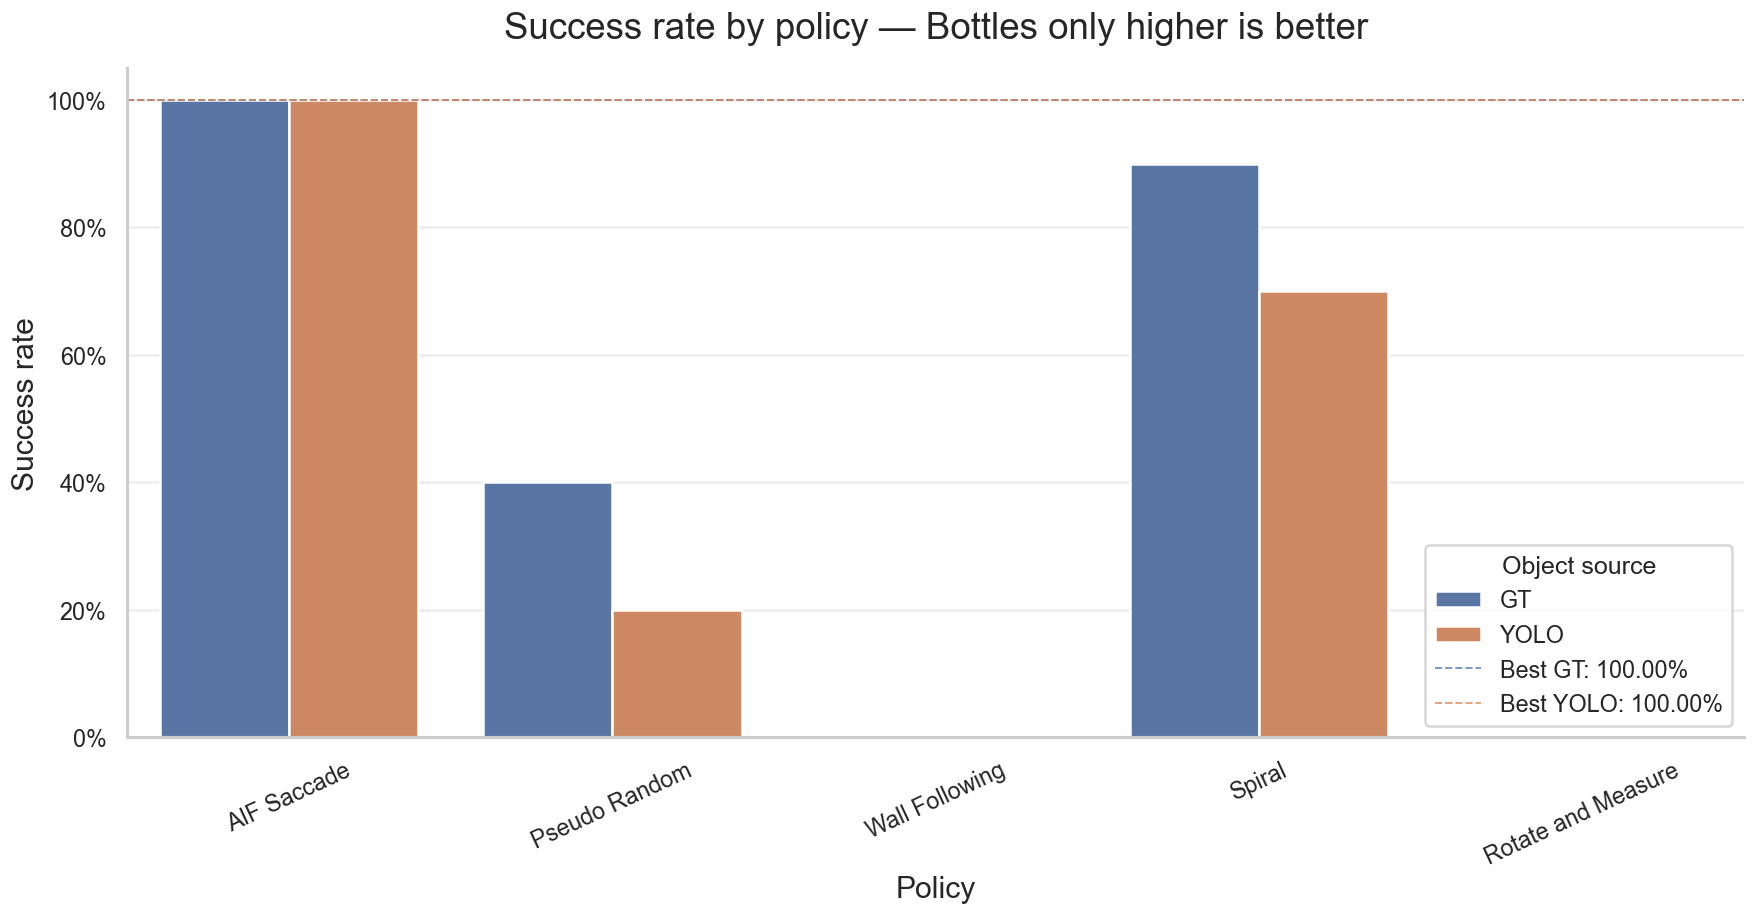

Saved figure: figures_eval_comparison/mixed__success.png


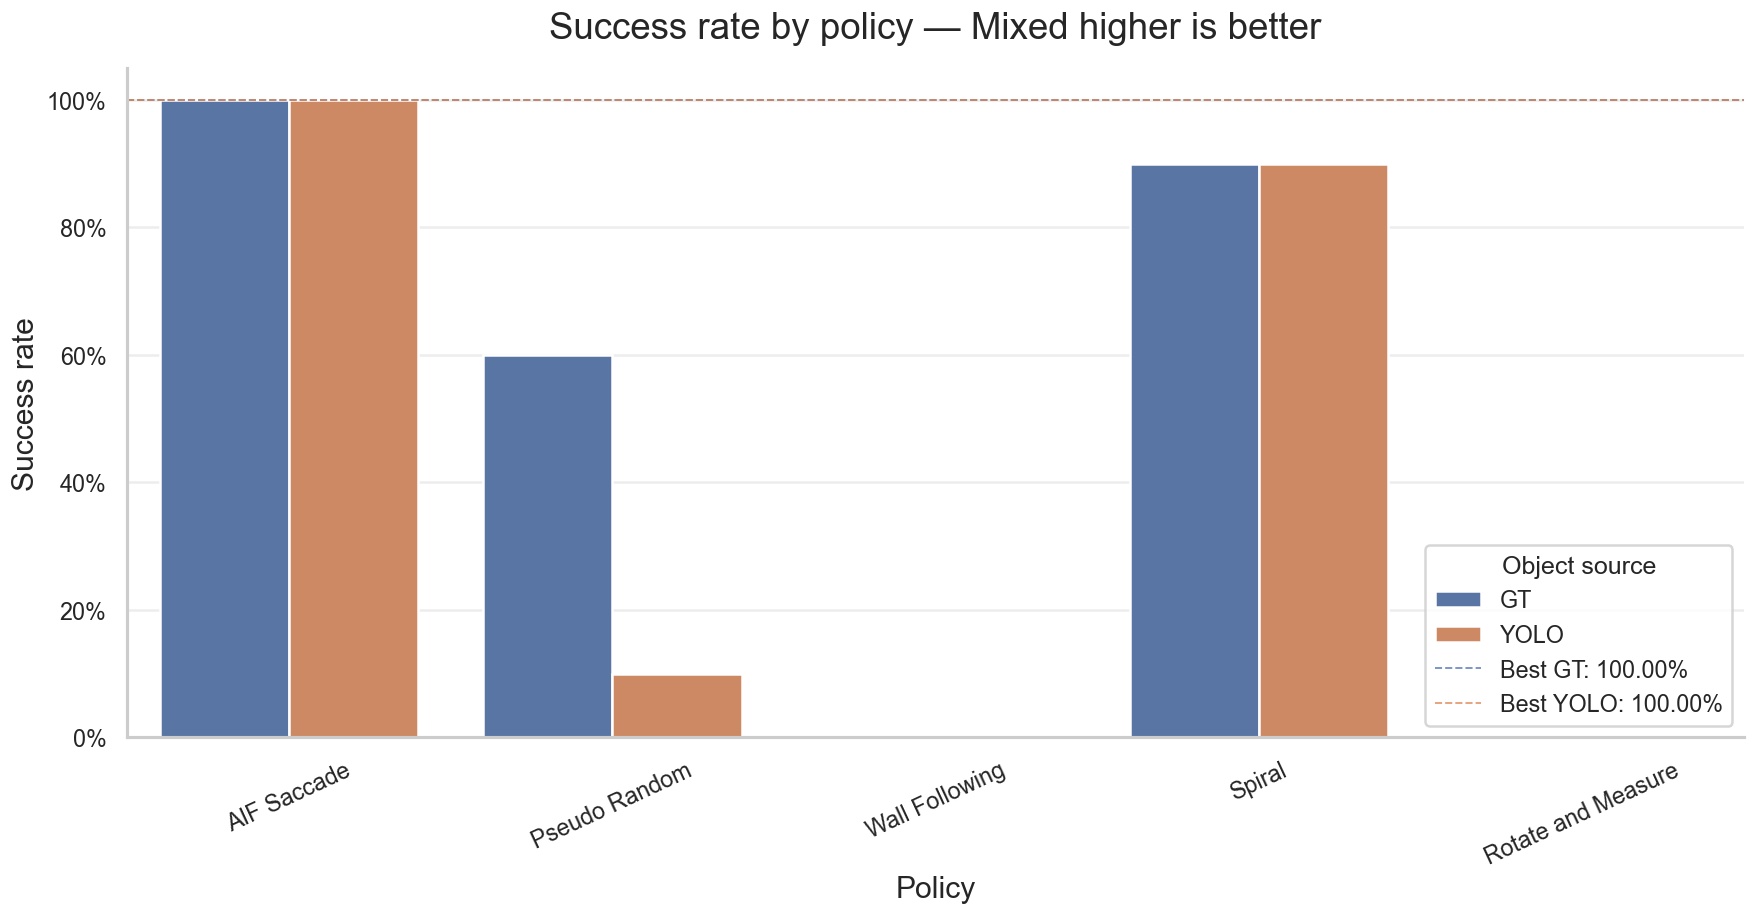

Saved figure: figures_eval_comparison/bottles_only__detected_objects_ratio.png


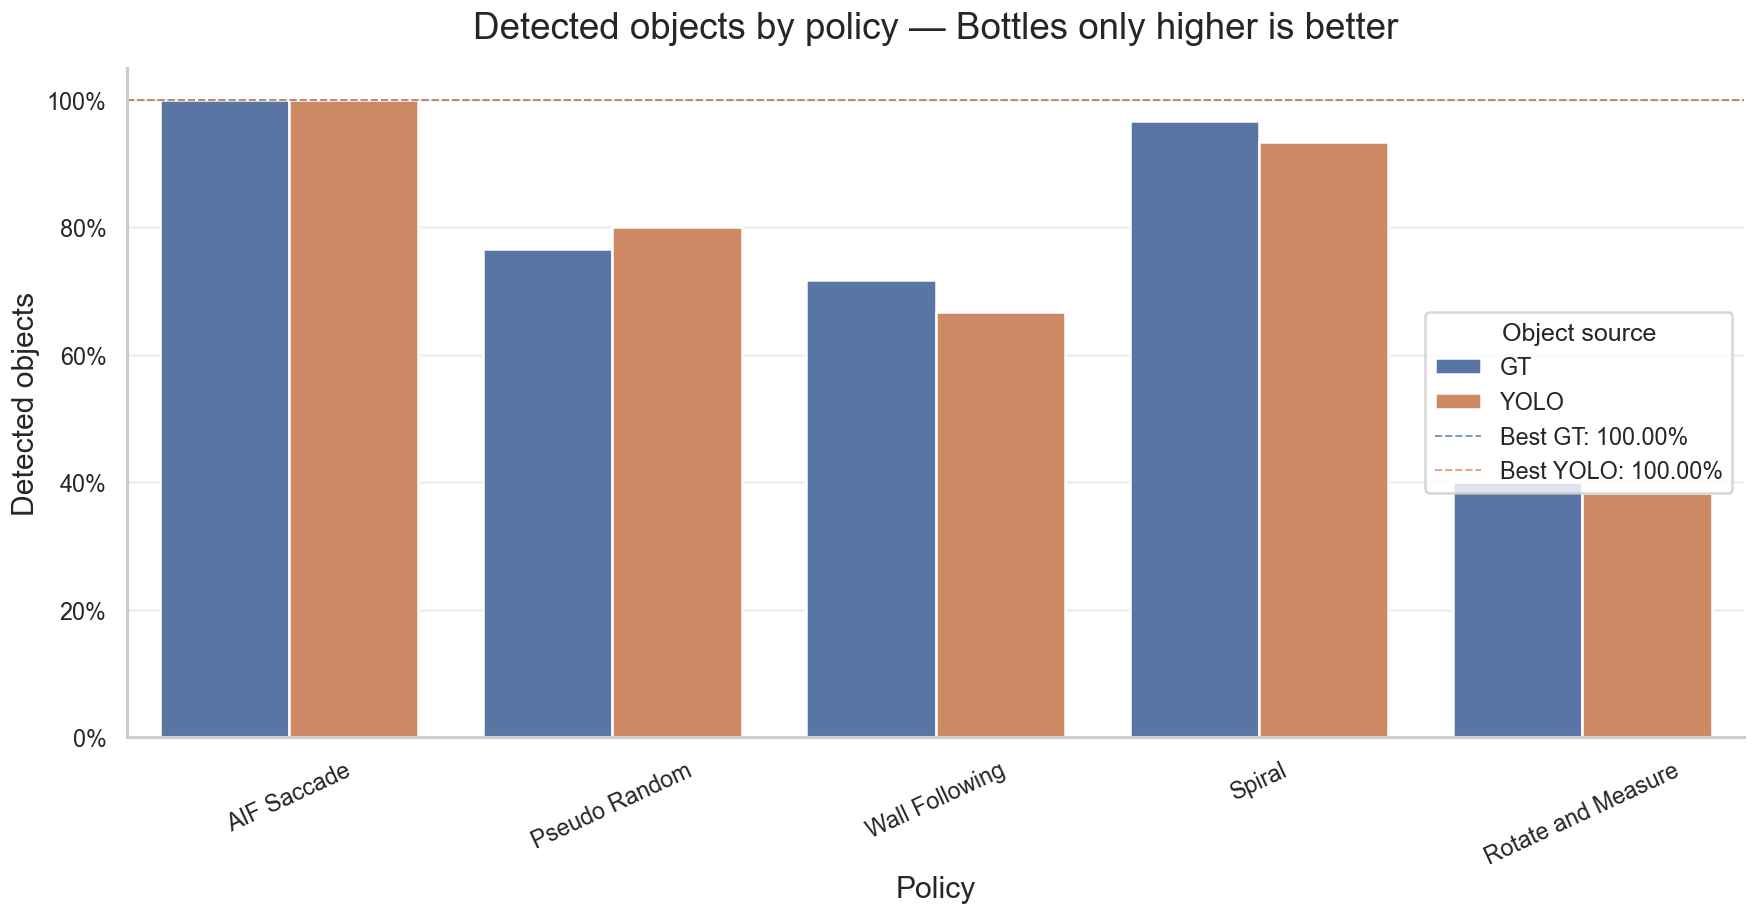

Saved figure: figures_eval_comparison/mixed__detected_objects_ratio.png


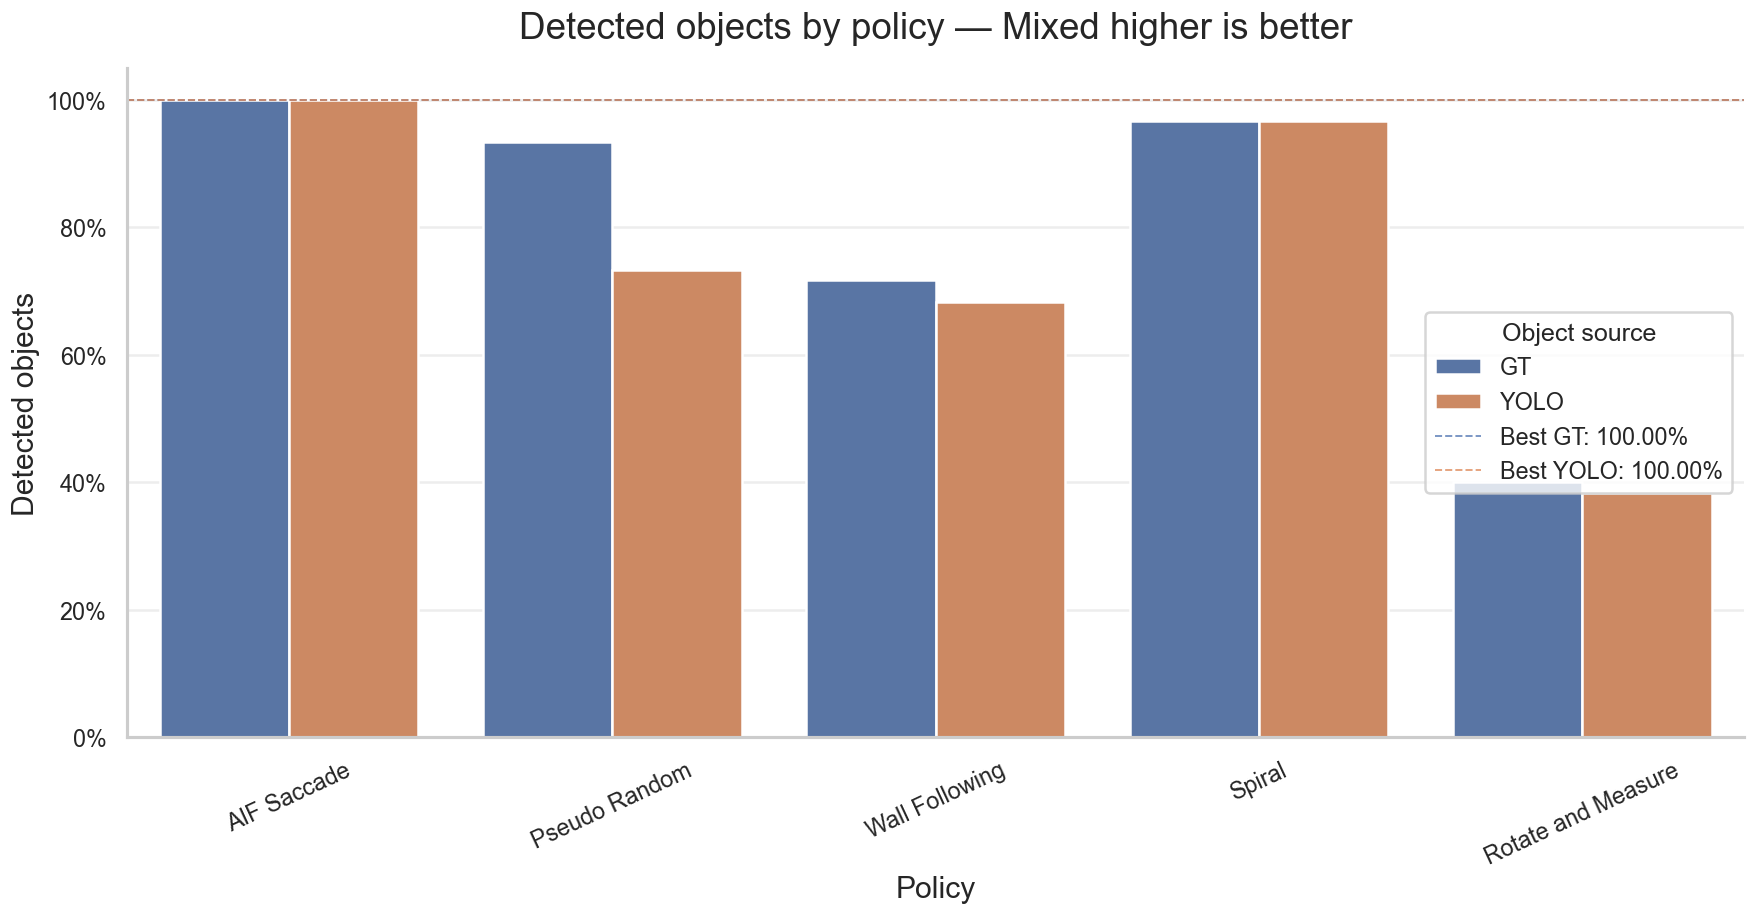

Saved figure: figures_eval_comparison/bottles_only__elapsed_s.png


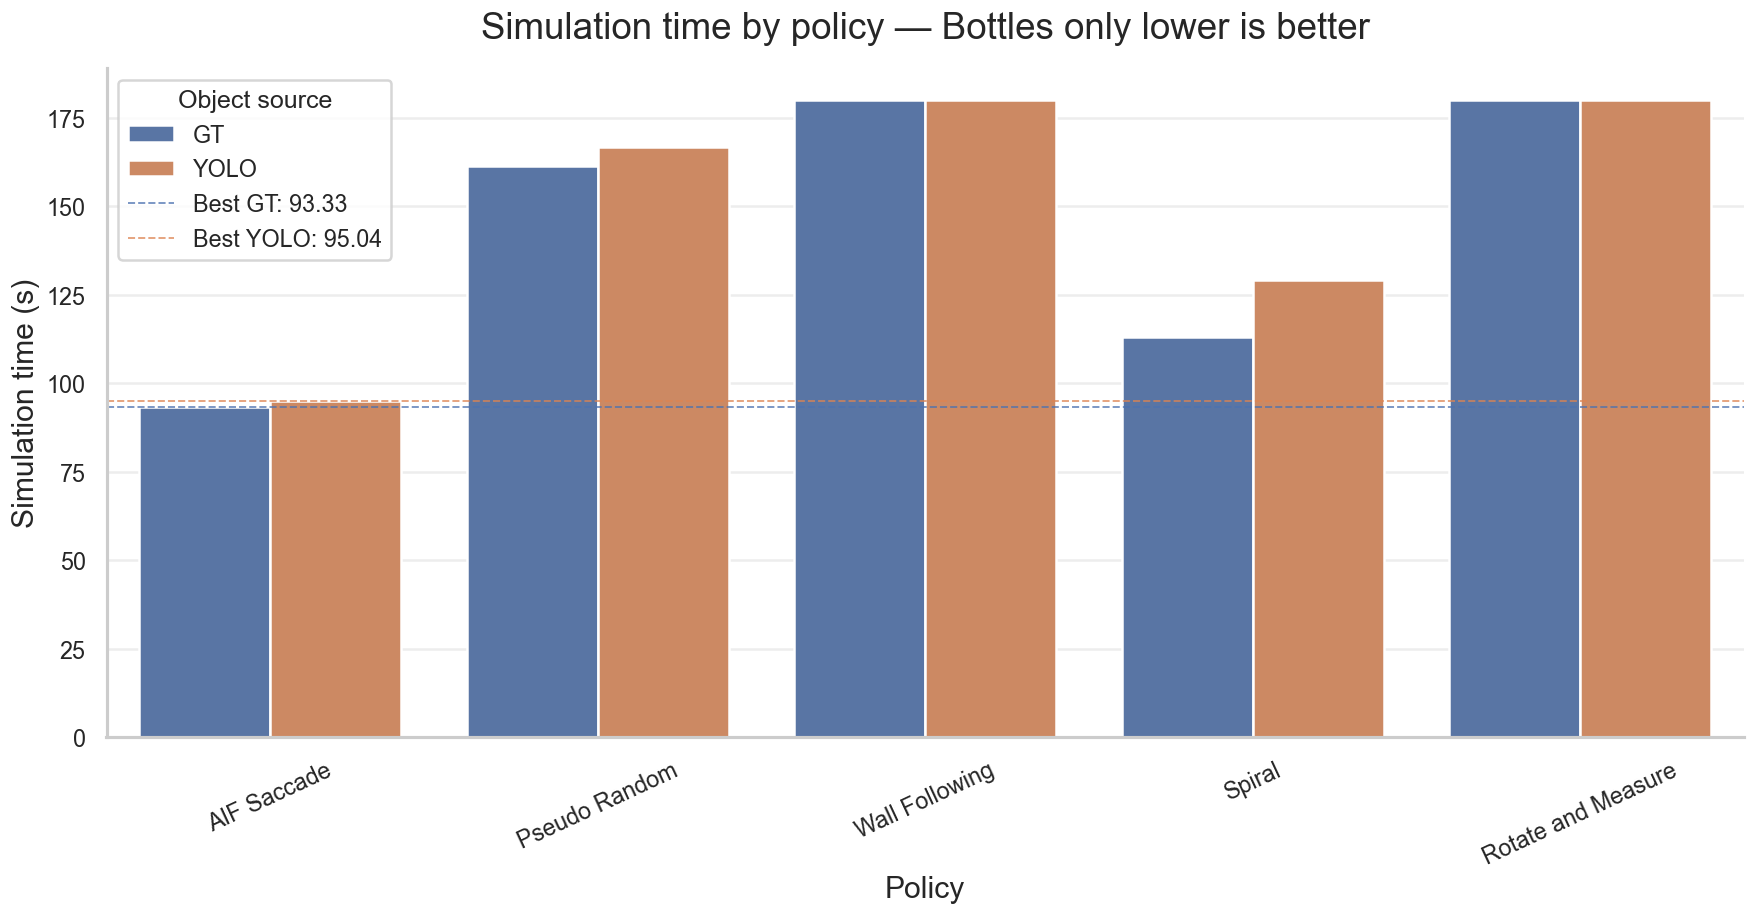

Saved figure: figures_eval_comparison/mixed__elapsed_s.png


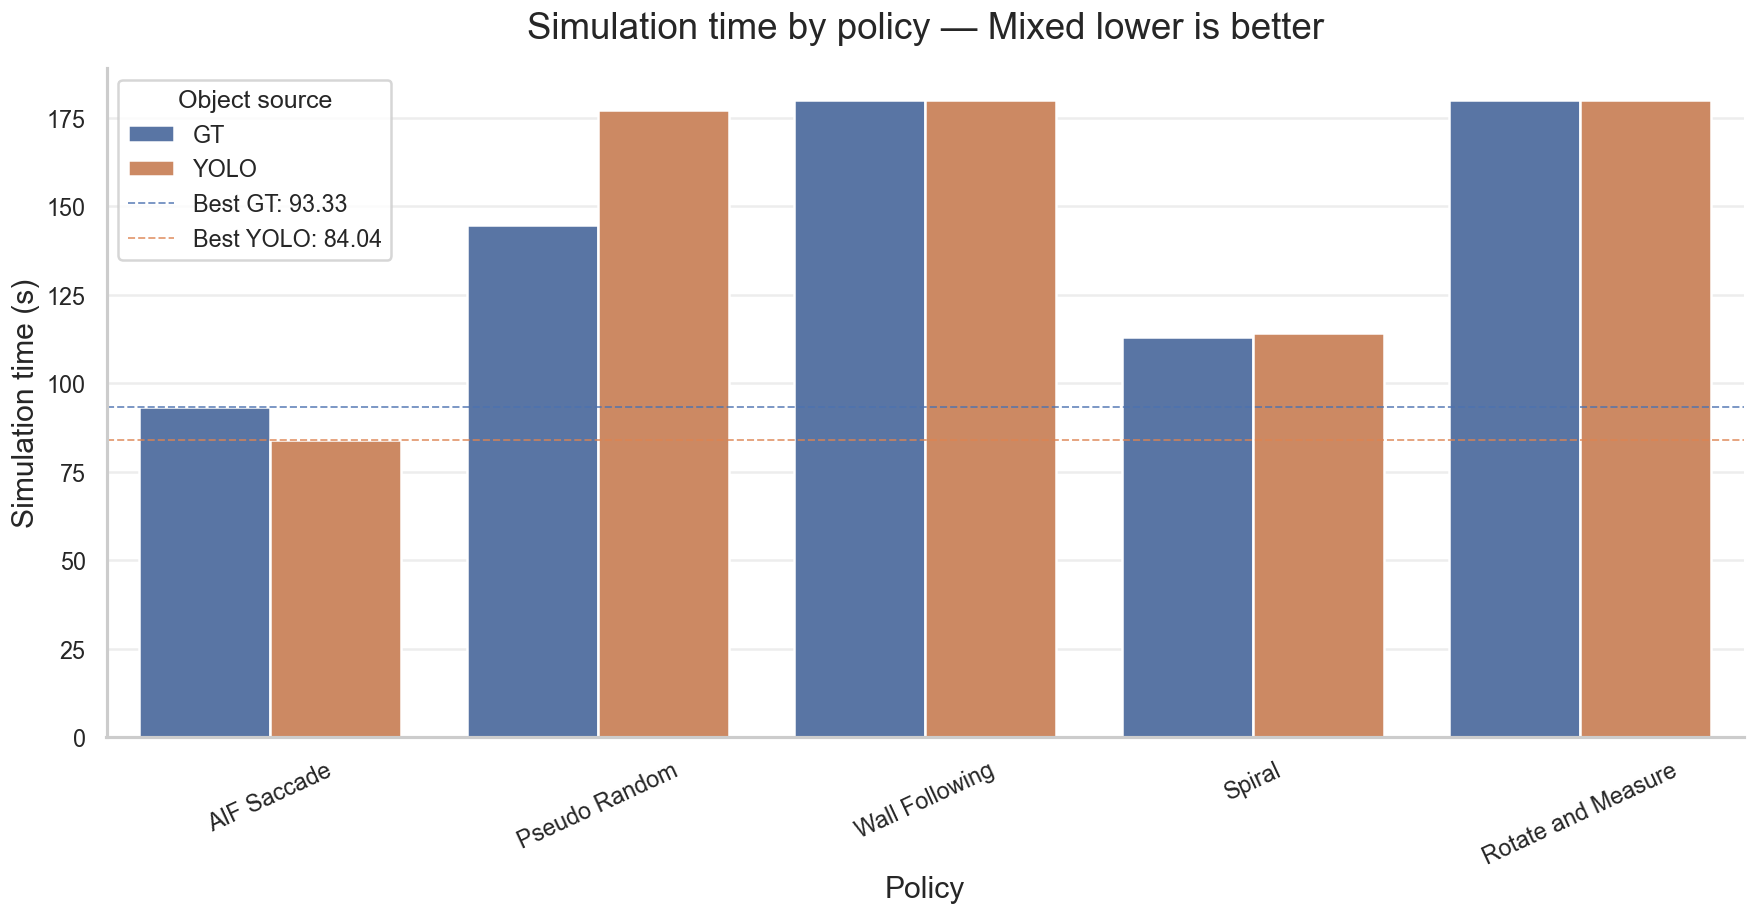

Saved figure: figures_eval_comparison/bottles_only__found_count.png


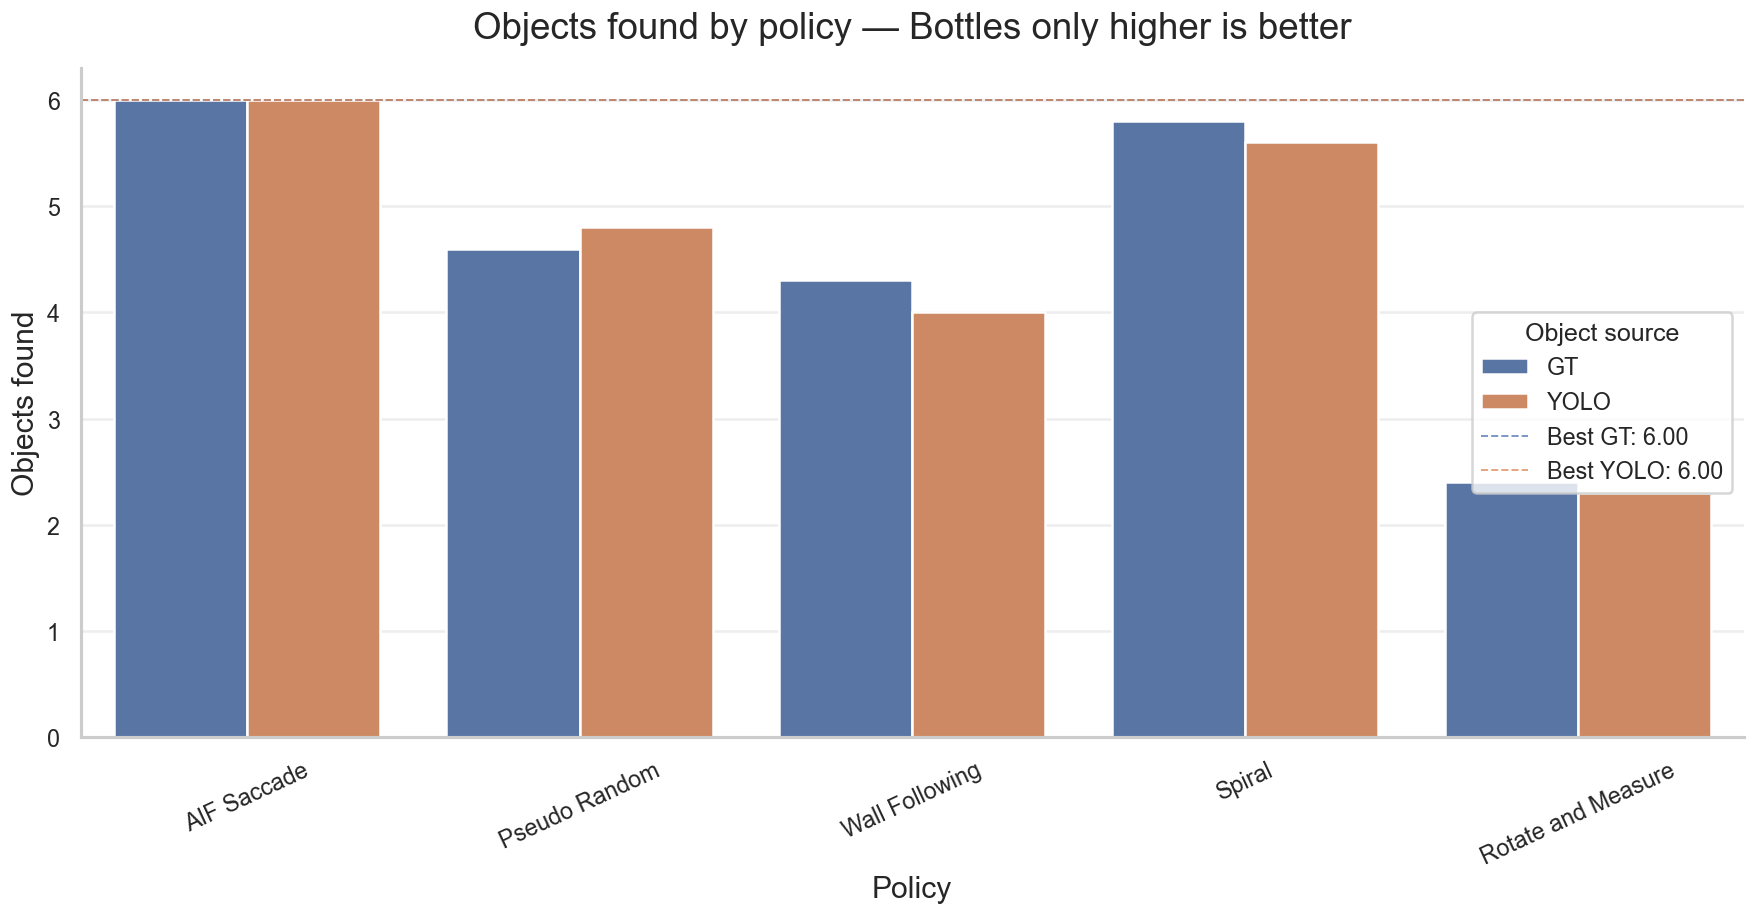

Saved figure: figures_eval_comparison/mixed__found_count.png


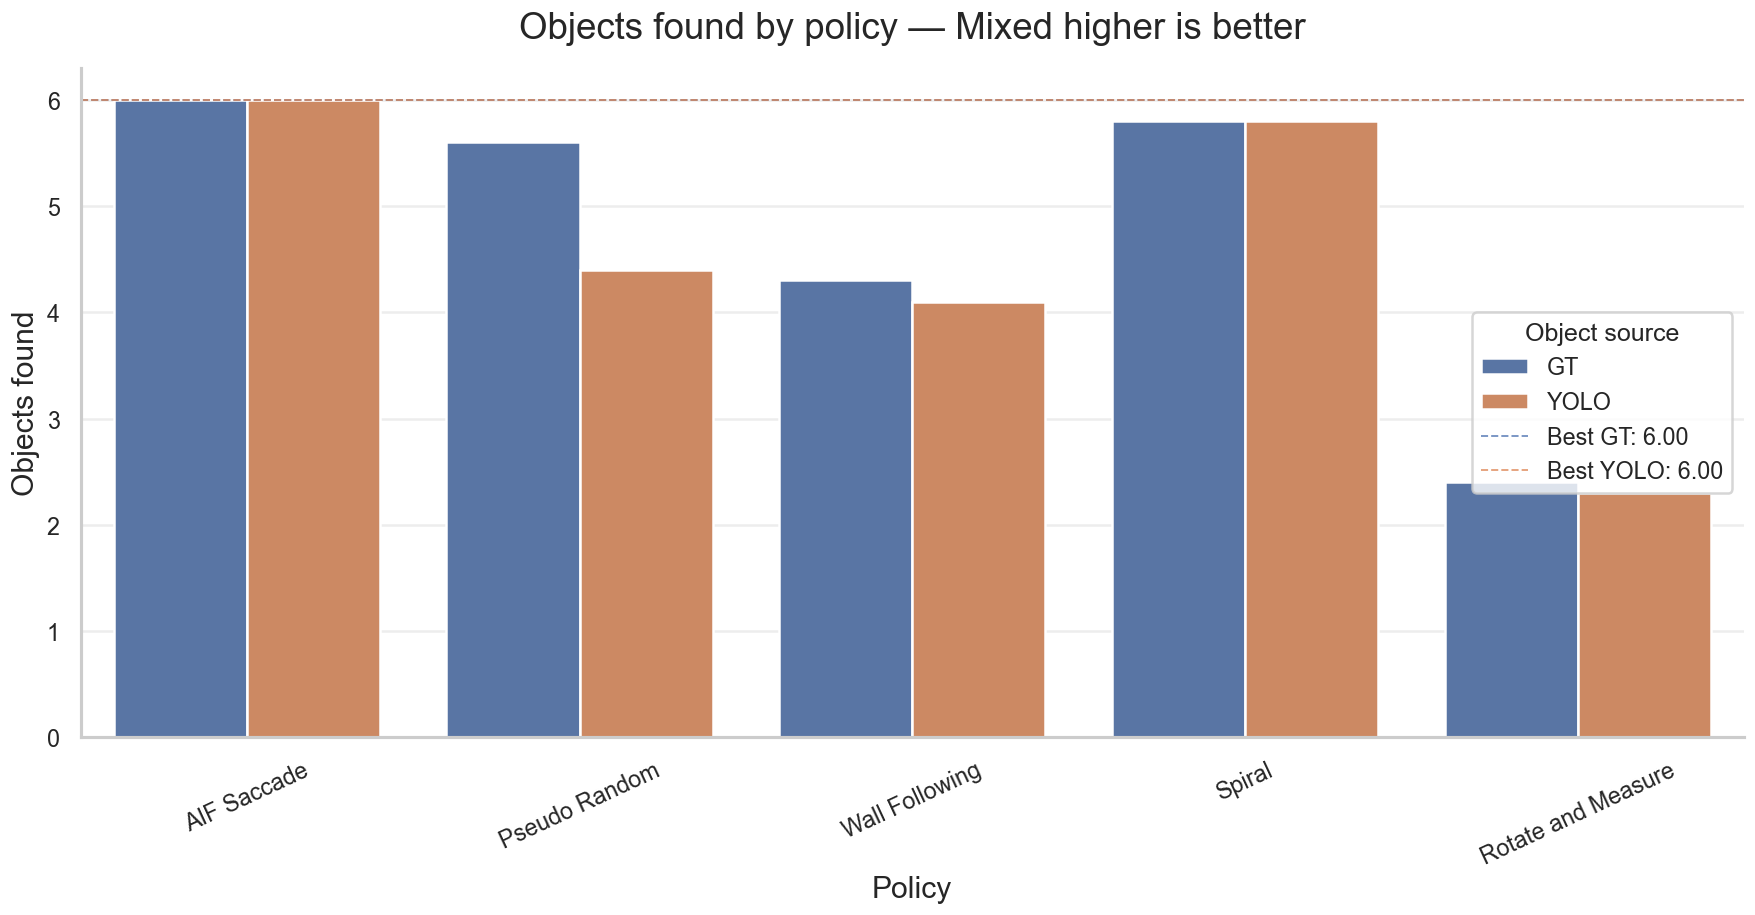

Saved figure: figures_eval_comparison/bottles_only__remaining_objects.png


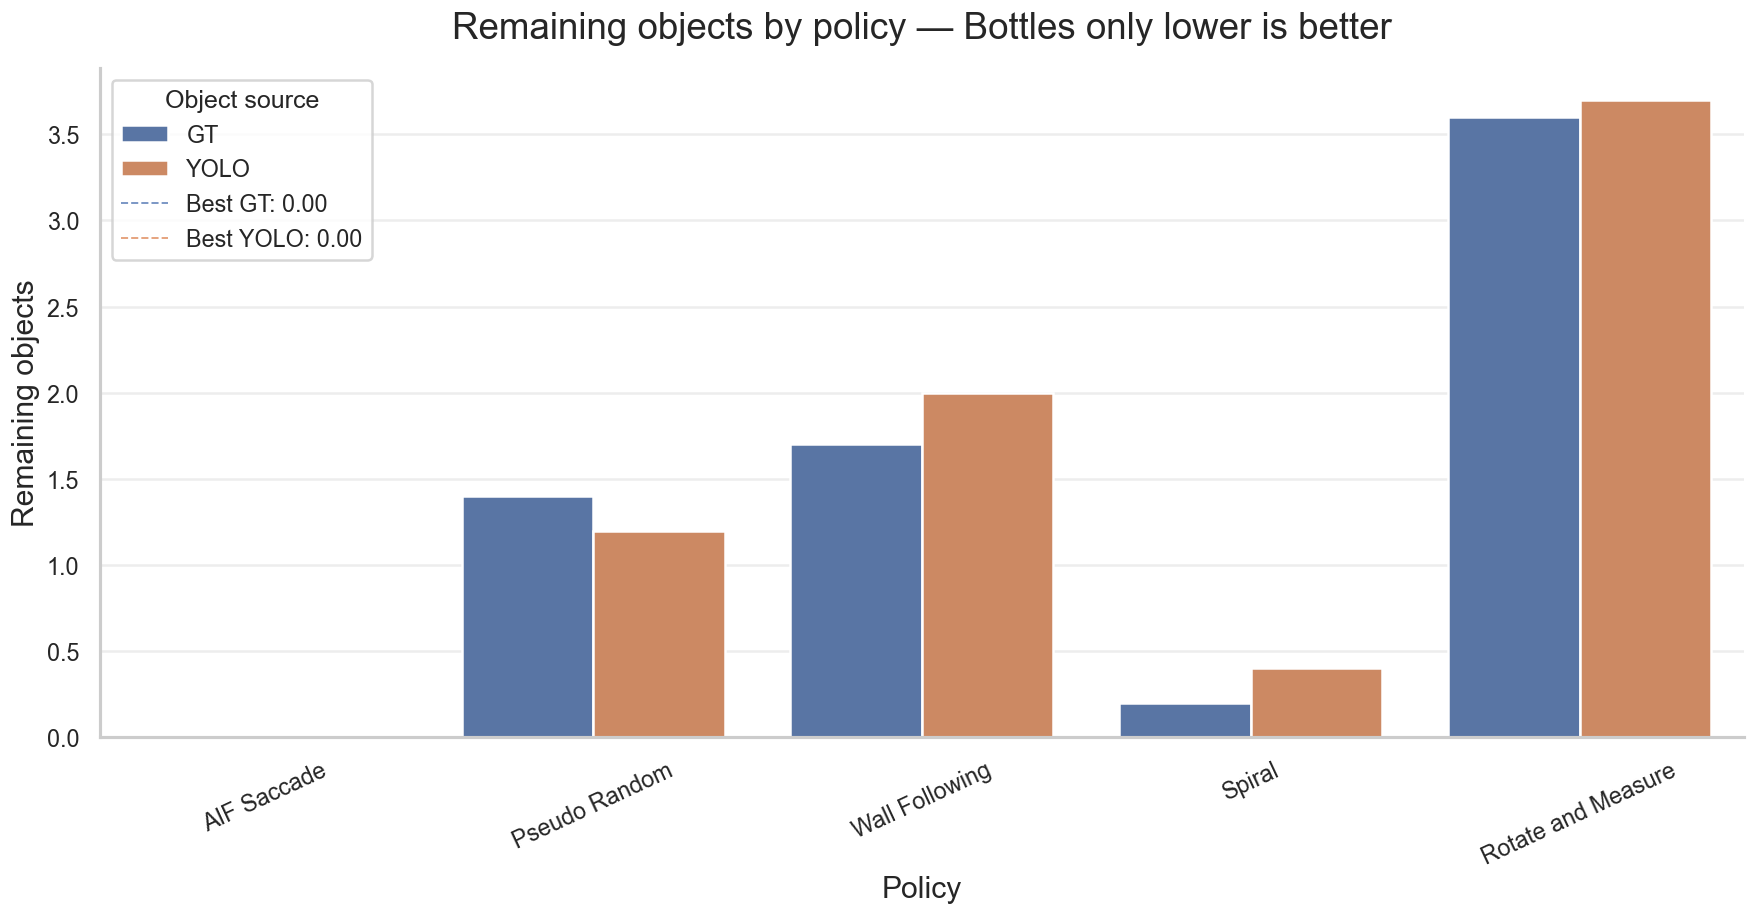

Saved figure: figures_eval_comparison/mixed__remaining_objects.png


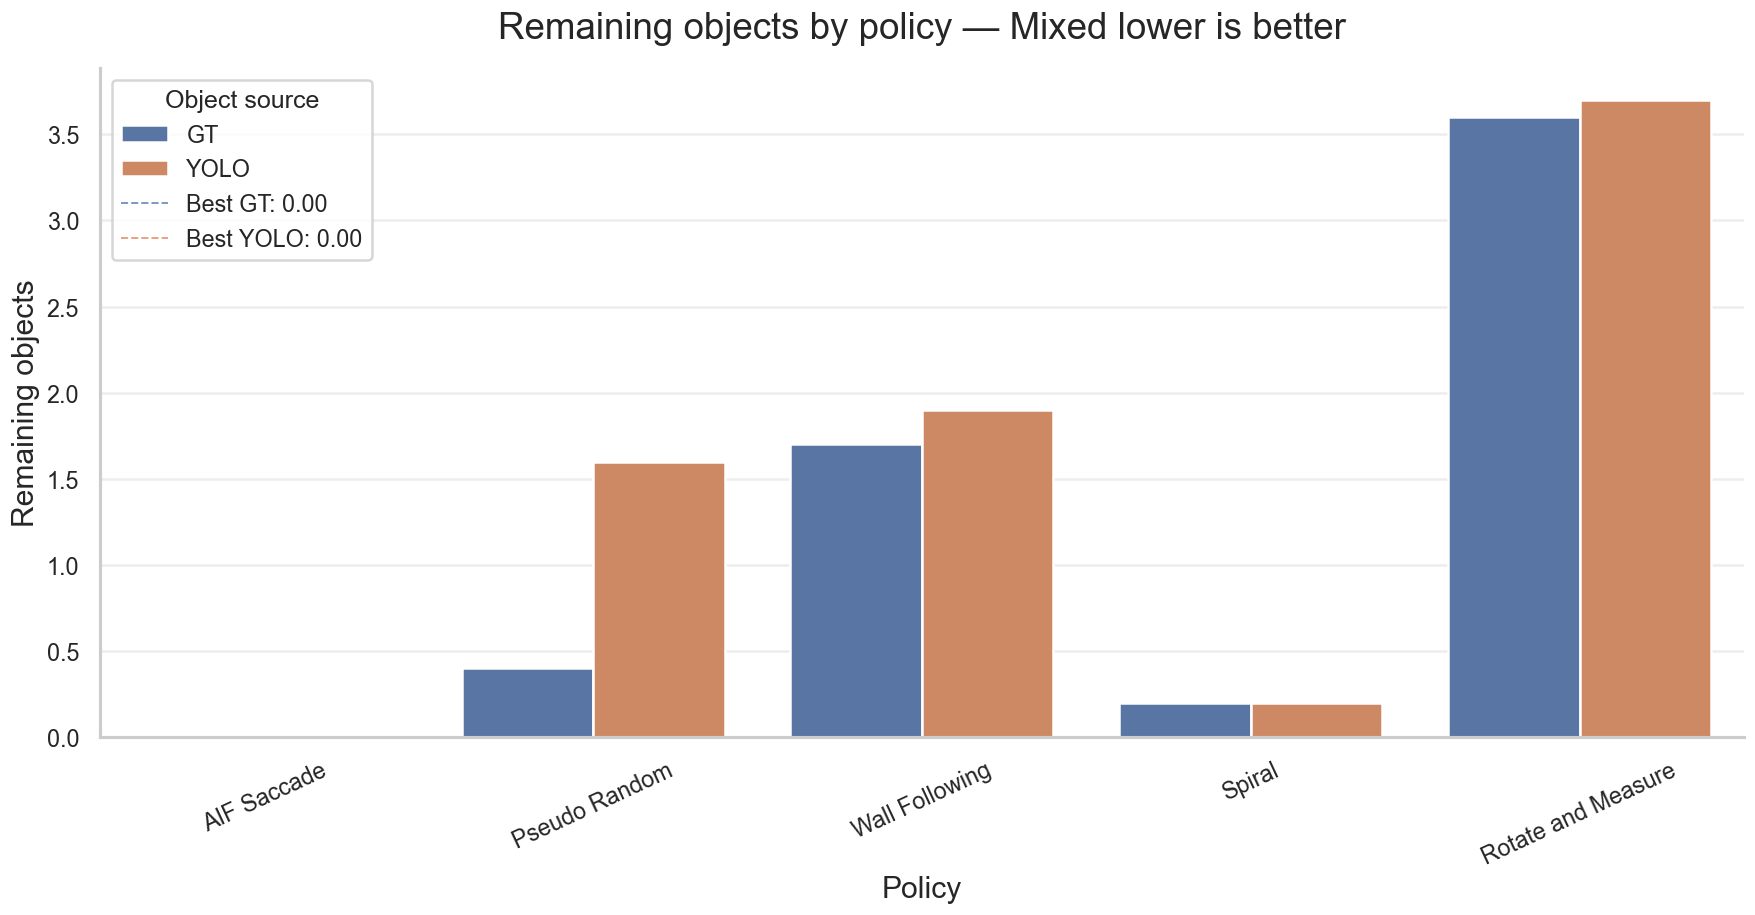

Saved figure: figures_eval_comparison/bottles_only__coverage_ratio.png


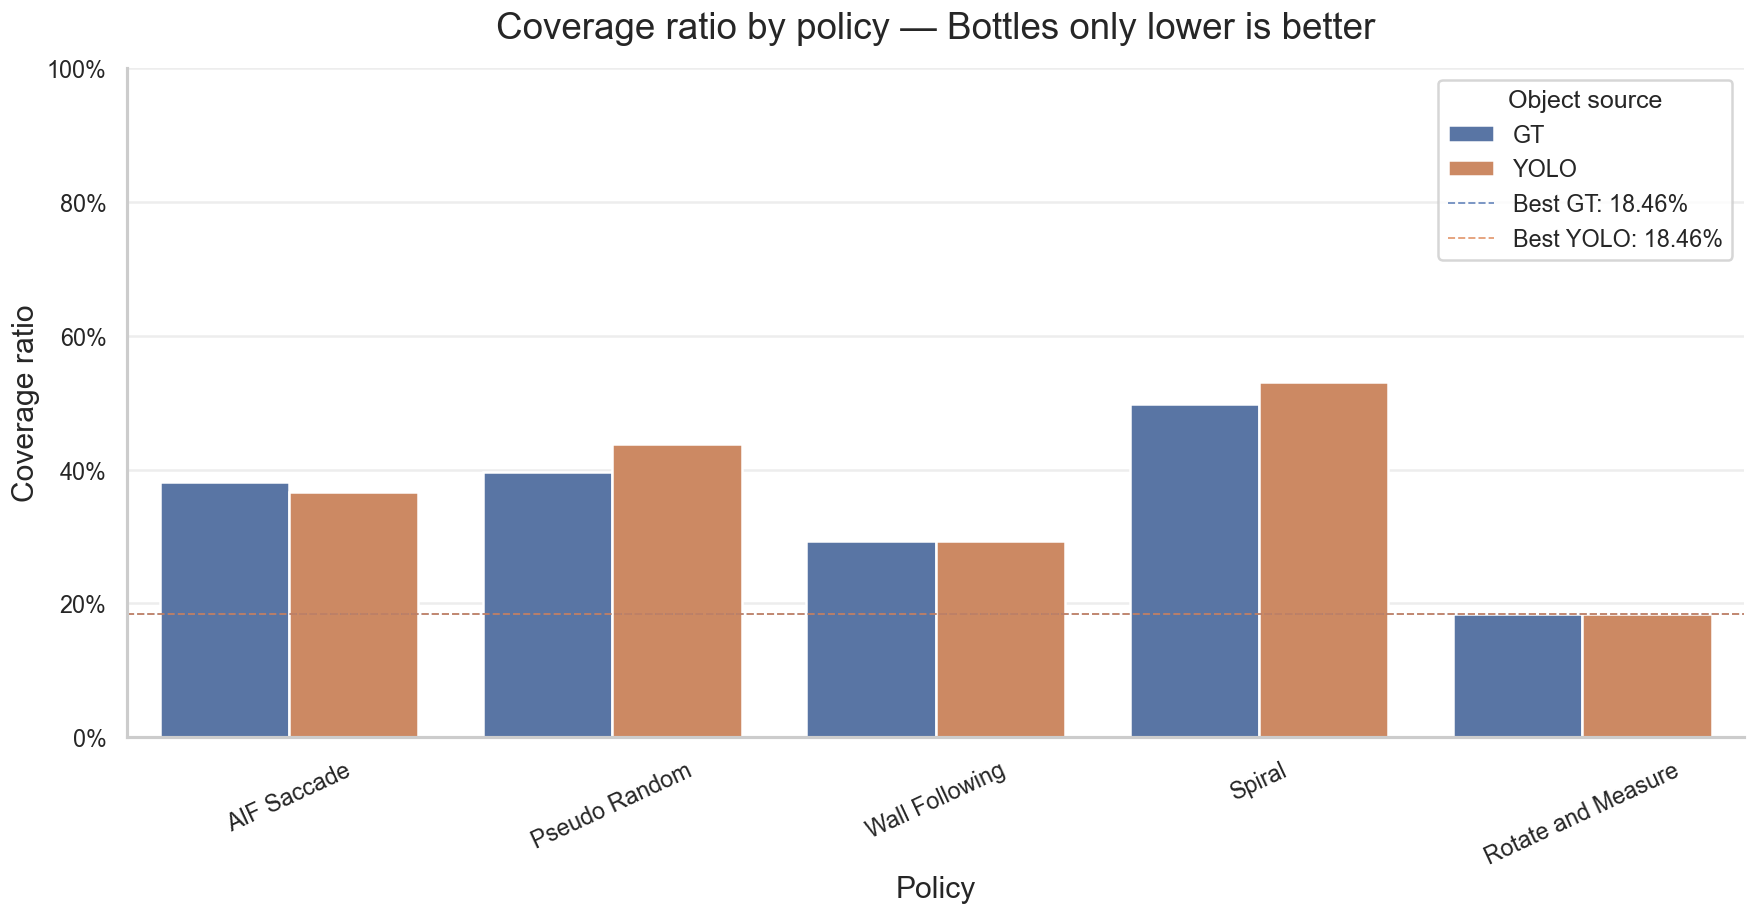

Saved figure: figures_eval_comparison/mixed__coverage_ratio.png


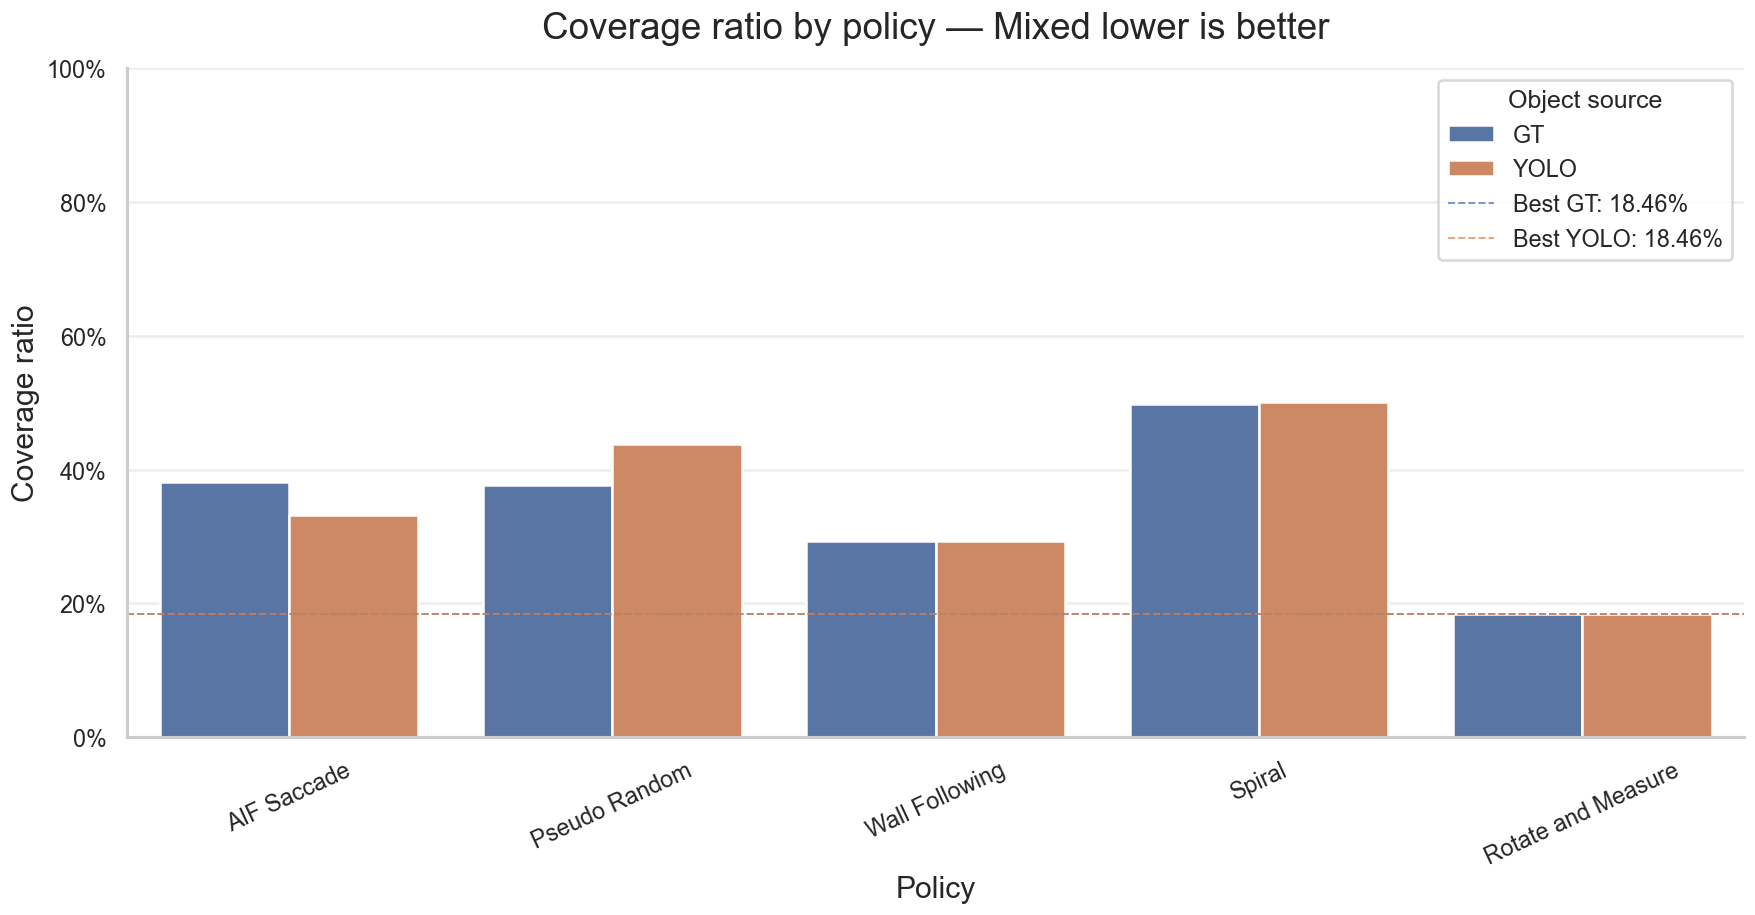

In [7]:
for metric in BASE_METRICS:
    if not metric_is_available(runs_df, metric):
        print(f"Skipping {metric}: not available.")
        continue

    for dataset in dataset_order:
        plot_metric_bar(metric, dataset)

Classification metrics found: ['overall_claim_precision', 'object_cell_class_accuracy', 'unique_claims_evaluated', 'correct_class_claims', 'wrong_class_claims', 'empty_cell_claims', 'duplicate_claims_ignored']
Skipping Overall claim precision for Bottles only: no non-null values.
Saved figure: figures_eval_comparison/mixed__overall_claim_precision.png


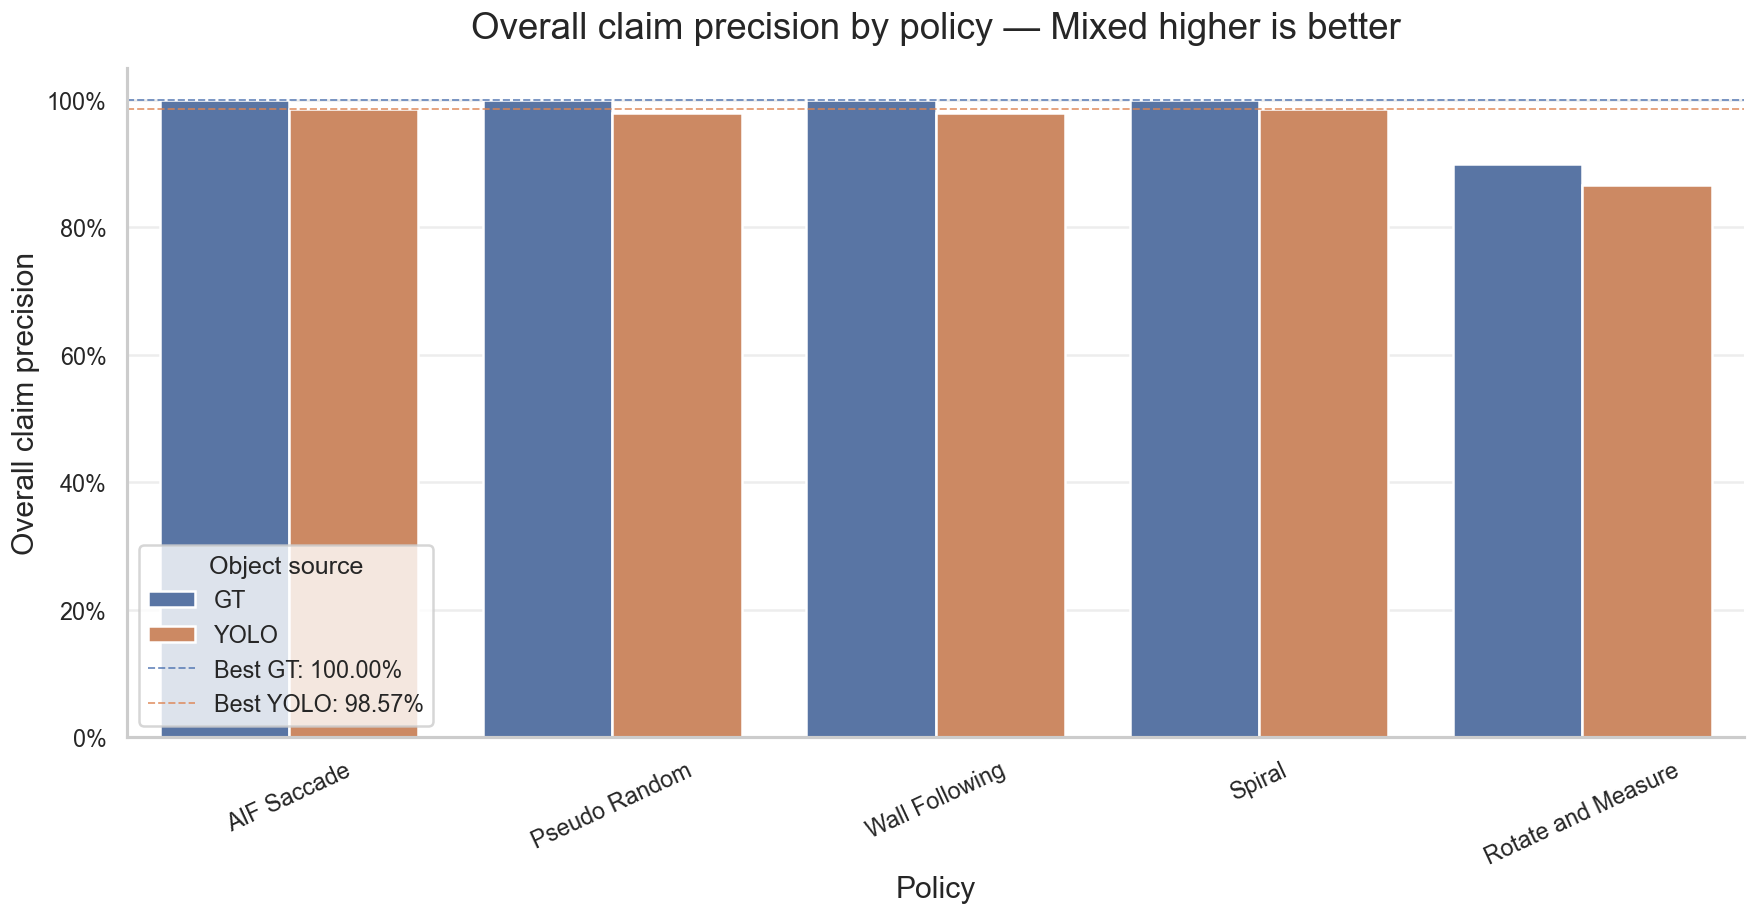

Skipping Object-cell class accuracy for Bottles only: no non-null values.
Saved figure: figures_eval_comparison/mixed__object_cell_class_accuracy.png


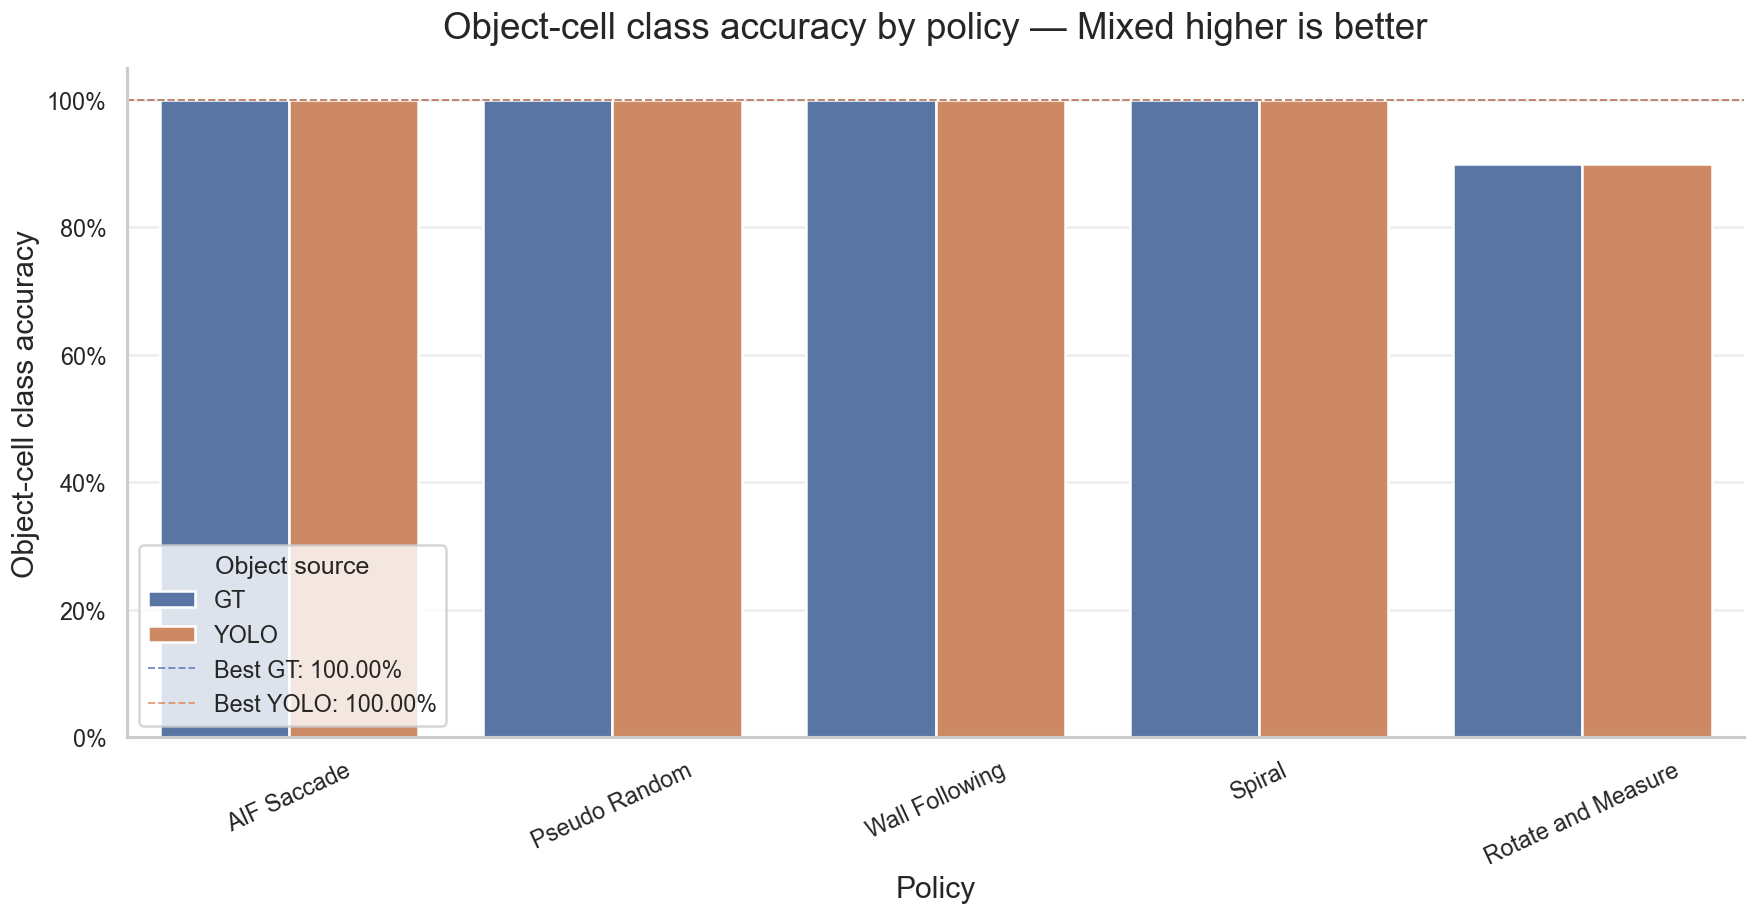

Skipping Unique claims evaluated for Bottles only: no non-null values.
Saved figure: figures_eval_comparison/mixed__unique_claims_evaluated.png


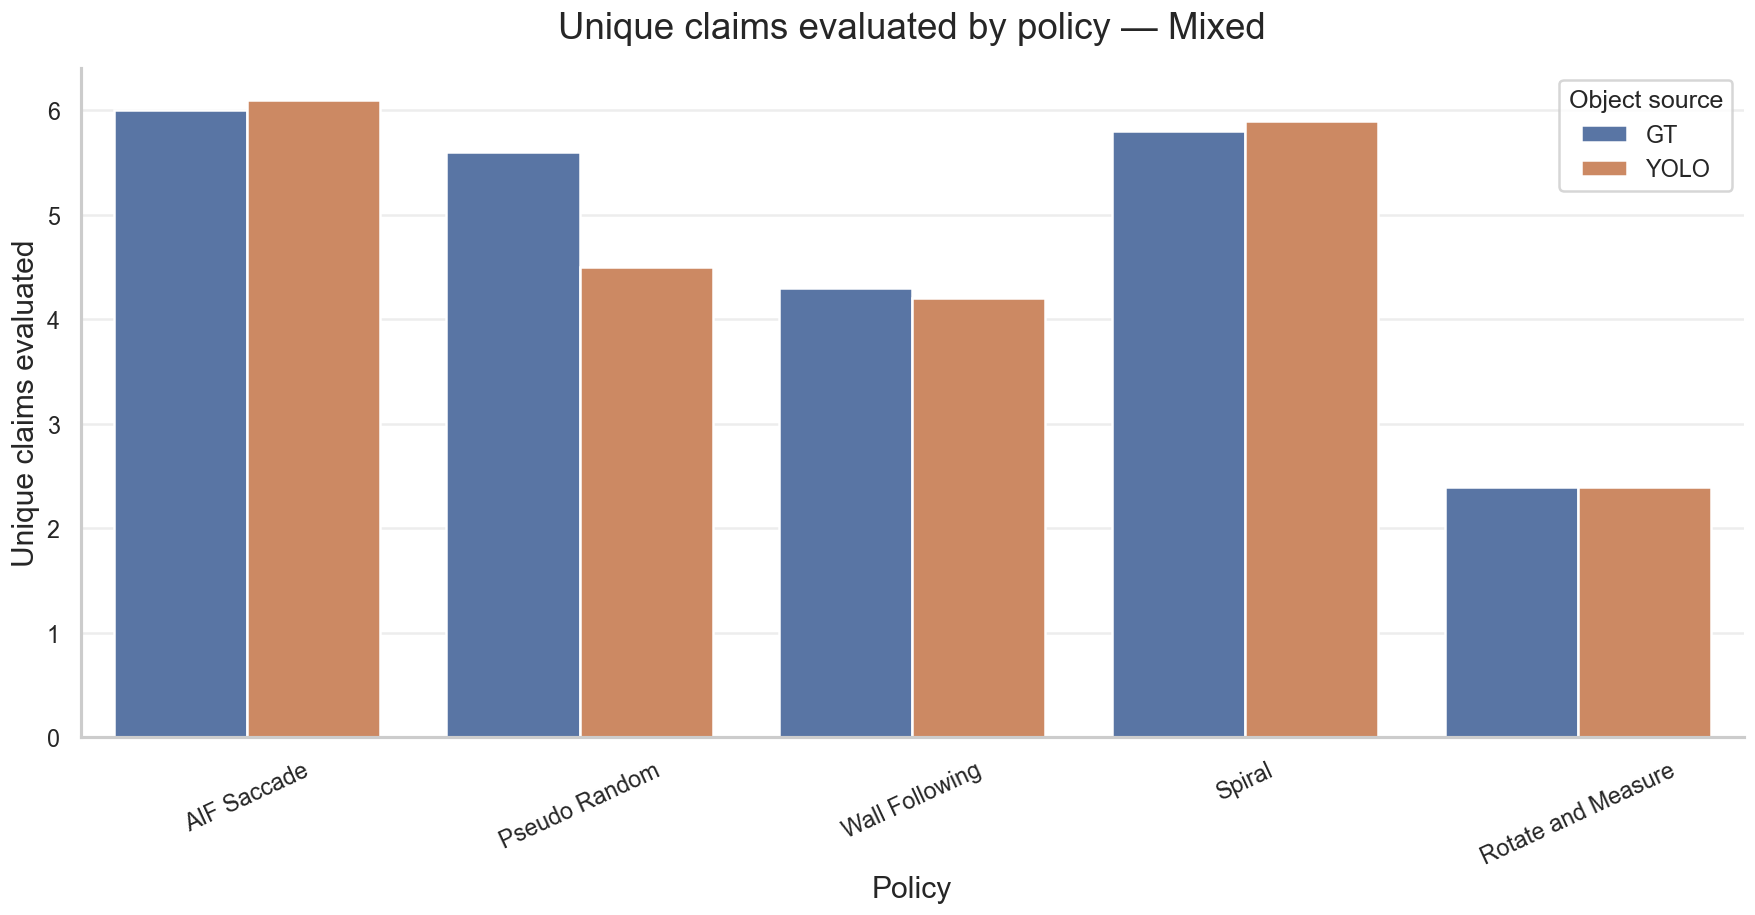

Skipping Correct class claims for Bottles only: no non-null values.
Saved figure: figures_eval_comparison/mixed__correct_class_claims.png


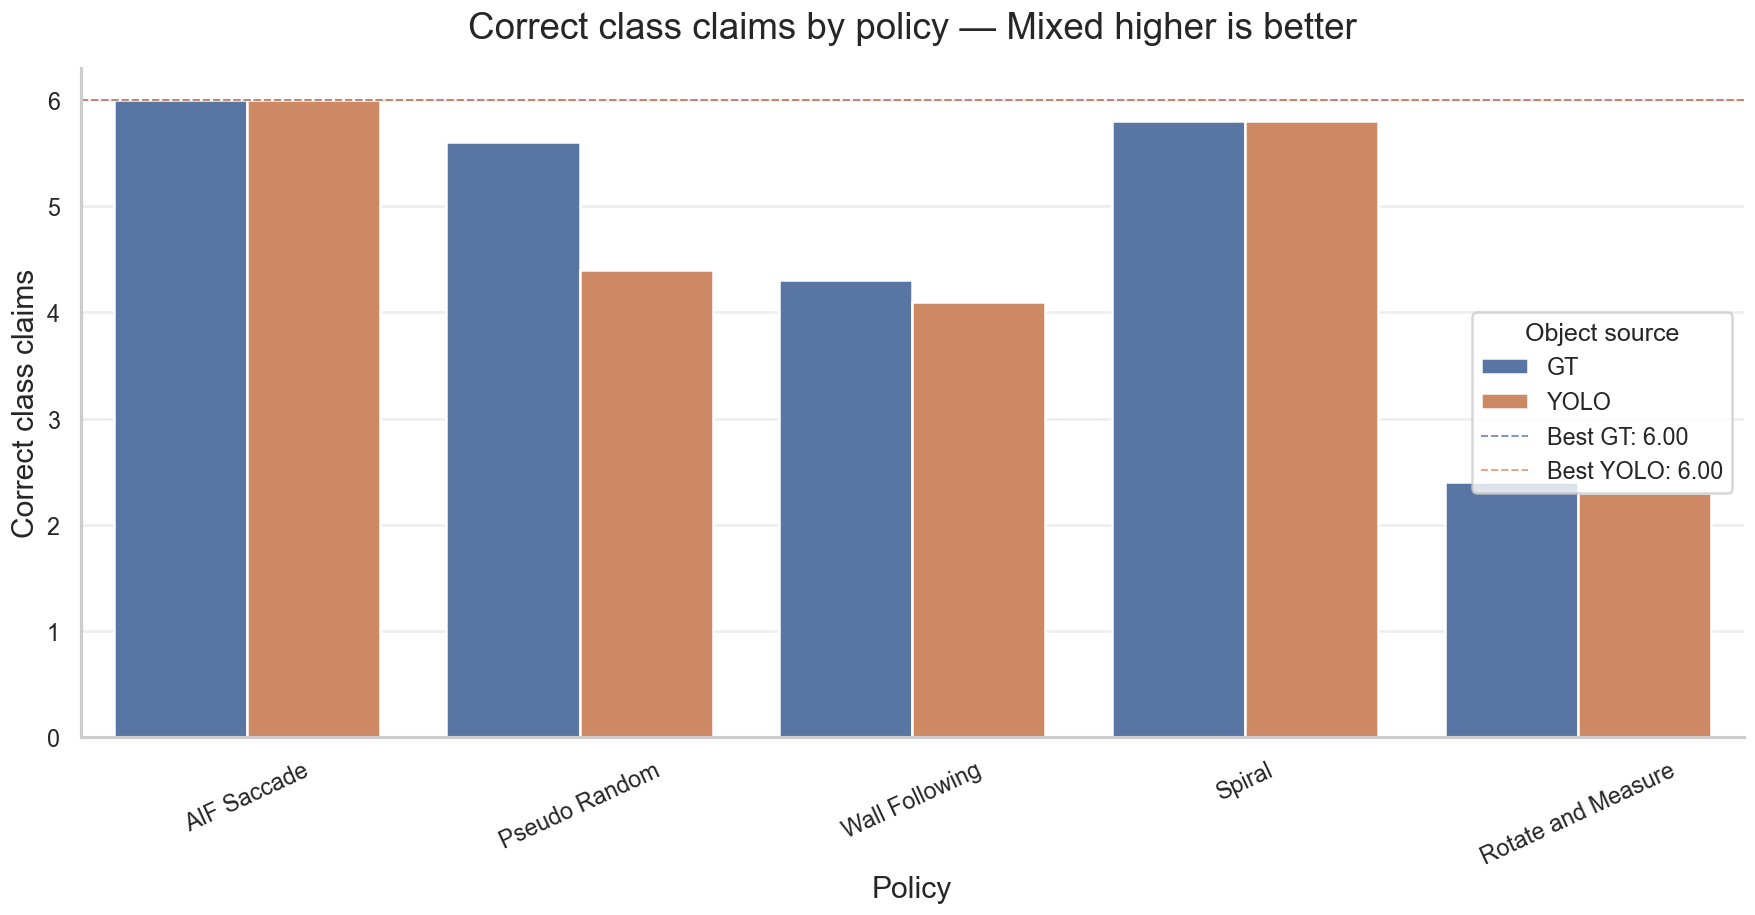

Skipping Wrong class claims for Bottles only: no non-null values.
Saved figure: figures_eval_comparison/mixed__wrong_class_claims.png


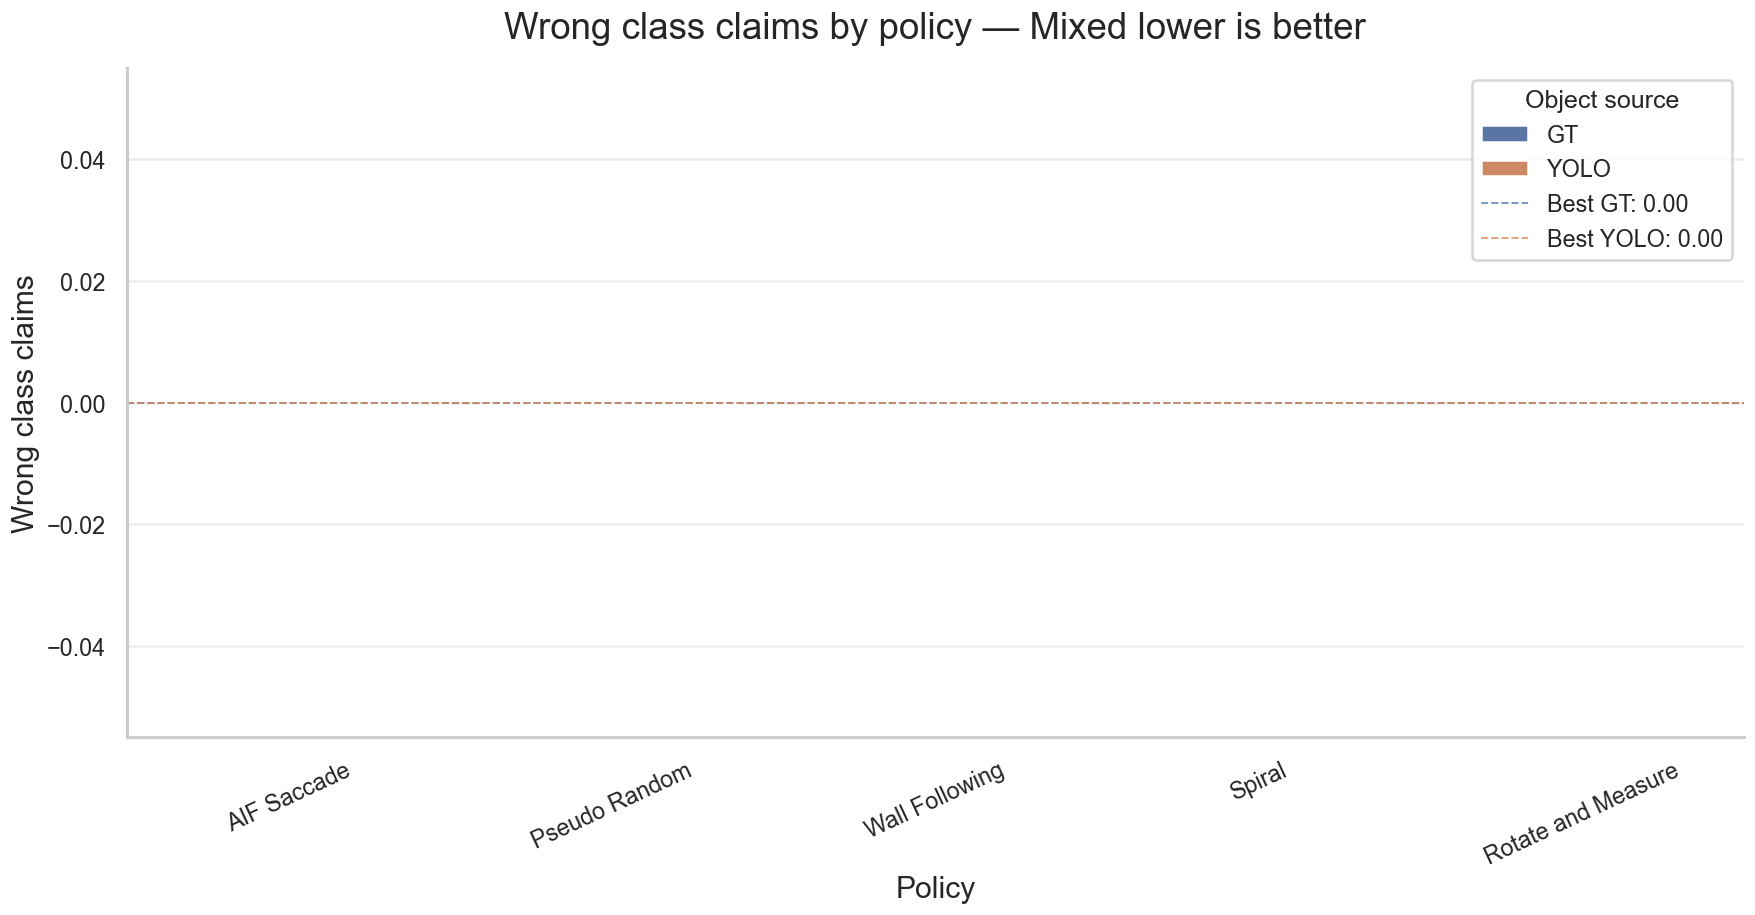

Skipping Empty-cell claims for Bottles only: no non-null values.
Saved figure: figures_eval_comparison/mixed__empty_cell_claims.png


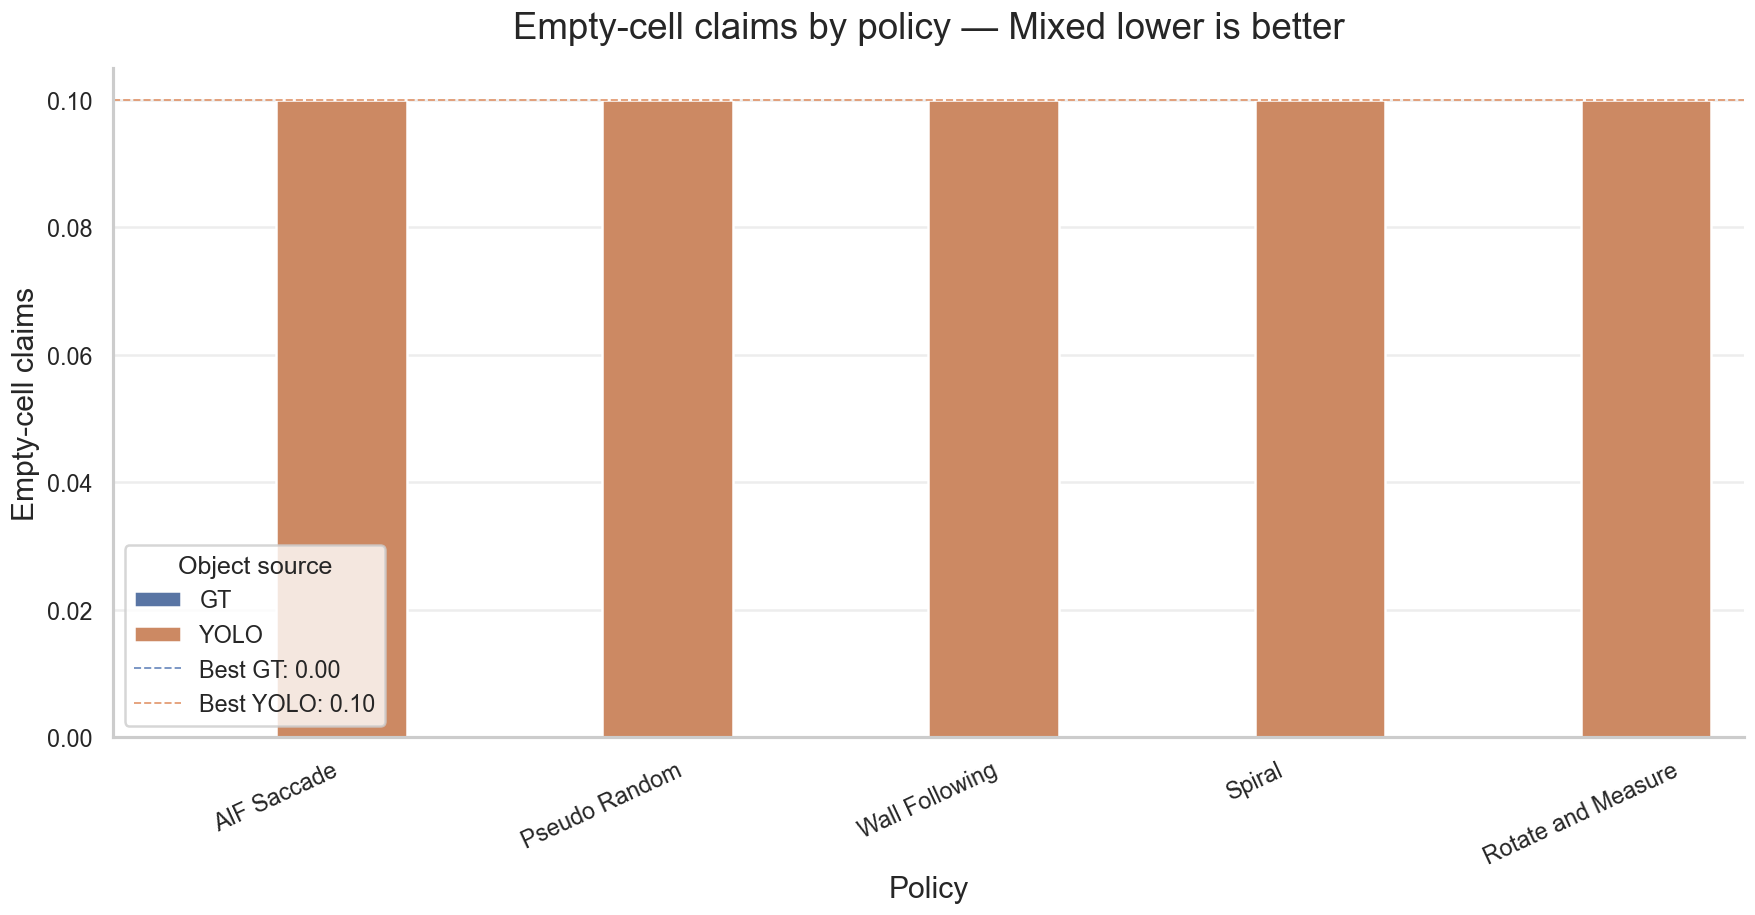

Skipping Duplicate claims ignored for Bottles only: no non-null values.
Saved figure: figures_eval_comparison/mixed__duplicate_claims_ignored.png


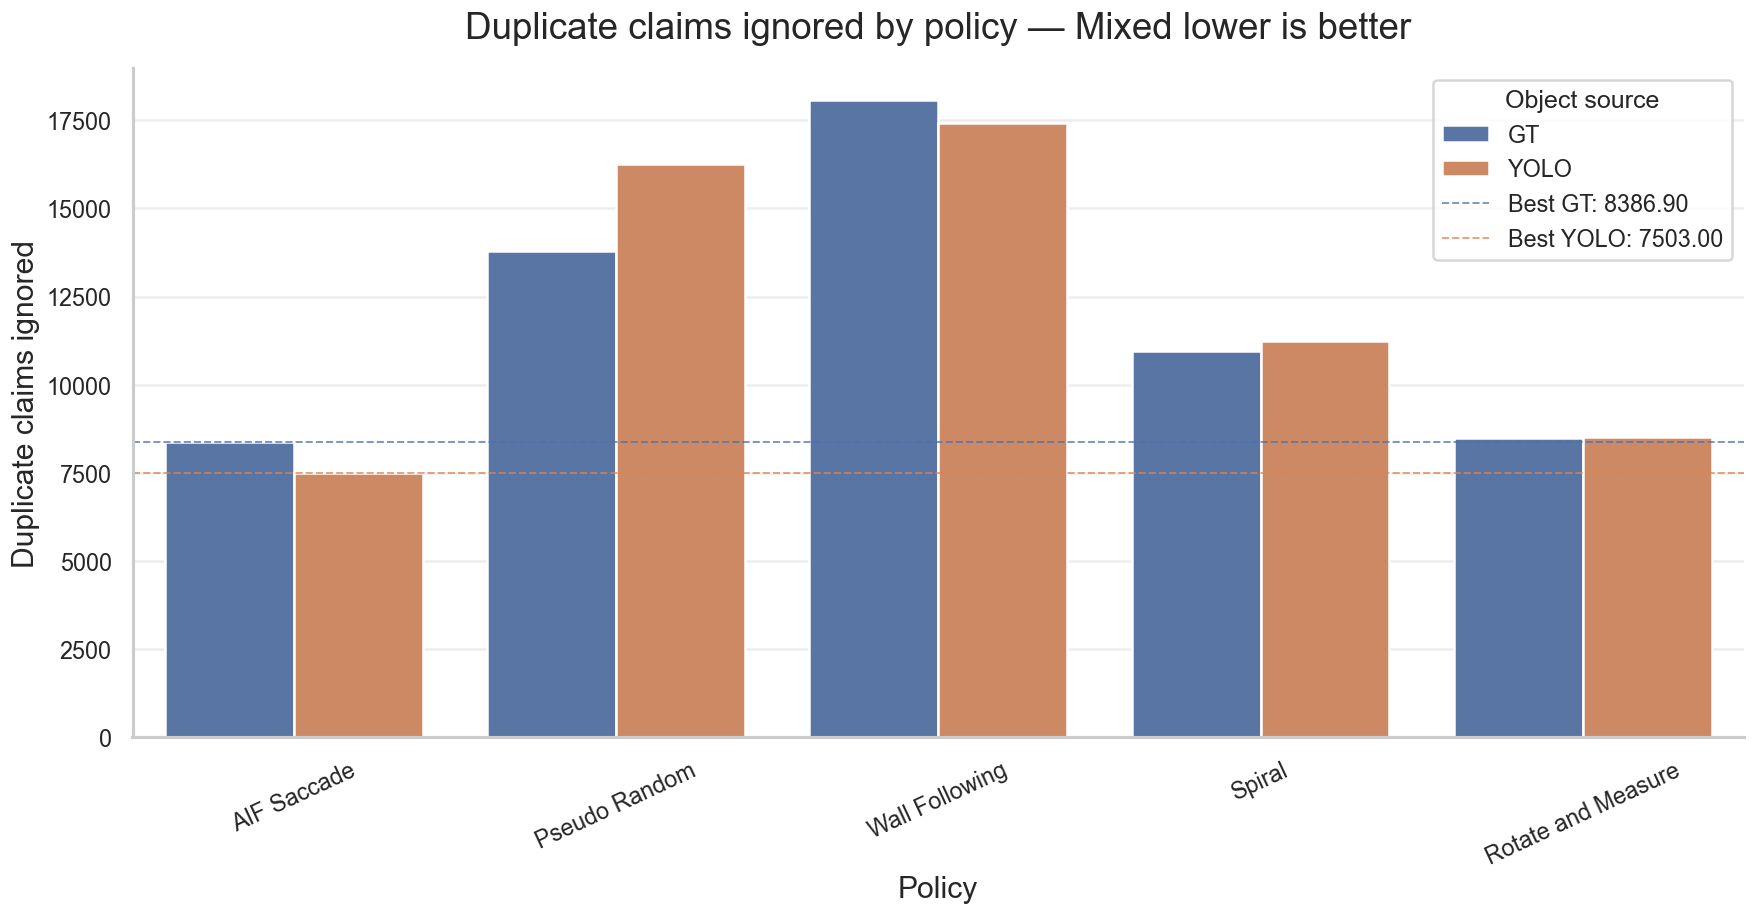

In [8]:
classification_available = [
    metric for metric in CLASSIFICATION_METRICS
    if metric_is_available(runs_df, metric)
]

if not classification_available:
    print("No classification metrics found. This is expected for bottles-only / GT-only reports.")
else:
    print("Classification metrics found:", classification_available)

    # Usually these are meaningful mainly for the Mixed dataset and YOLO detector,
    # but this loop will plot any dataset/condition where the metric exists.
    for metric in classification_available:
        for dataset in dataset_order:
            plot_metric_bar(metric, dataset)

In [9]:
def make_metric_table(metric):
    meta = ALL_METRICS[metric]
    table = (
        runs_df
        .groupby(["dataset", "policy_label", "detector"], observed=True)[metric]
        .mean()
        .reset_index()
        .pivot_table(
            index=["dataset", "policy_label"],
            columns="detector",
            values=metric,
            observed=True,
        )
        .reset_index()
    )

    # Add YOLO - GT delta when both exist.
    if "GT" in table.columns and "YOLO" in table.columns:
        table["YOLO_minus_GT"] = table["YOLO"] - table["GT"]

    if meta.get("kind") == "percentage":
        value_cols = [c for c in table.columns if c not in ["dataset", "policy_label"]]
        for c in value_cols:
            table[c] = table[c].map(lambda x: np.nan if pd.isna(x) else 100 * x)

    return table


for metric in available_metrics:
    display(Markdown(f"### {ALL_METRICS[metric]['label']}"))
    display(make_metric_table(metric))

### Success rate

detector,dataset,policy_label,GT,YOLO,YOLO_minus_GT
0,Bottles only,AIF Saccade,100.0,100.0,0.0
1,Bottles only,Pseudo Random,40.0,20.0,-20.0
2,Bottles only,Wall Following,0.0,0.0,0.0
3,Bottles only,Spiral,90.0,70.0,-20.0
4,Bottles only,Rotate and Measure,0.0,0.0,0.0
5,Mixed,AIF Saccade,100.0,100.0,0.0
6,Mixed,Pseudo Random,60.0,10.0,-50.0
7,Mixed,Wall Following,0.0,0.0,0.0
8,Mixed,Spiral,90.0,90.0,0.0
9,Mixed,Rotate and Measure,0.0,0.0,0.0


### Detected objects

detector,dataset,policy_label,GT,YOLO,YOLO_minus_GT
0,Bottles only,AIF Saccade,100.000000,100.000000,0.000000
1,Bottles only,Pseudo Random,76.666667,80.000000,3.333333
2,Bottles only,Wall Following,71.666667,66.666667,-5.000000
3,Bottles only,Spiral,96.666667,93.333333,-3.333333
4,Bottles only,Rotate and Measure,40.000000,38.333333,-1.666667
5,Mixed,AIF Saccade,100.000000,100.000000,0.000000
6,Mixed,Pseudo Random,93.333333,73.333333,-20.000000
7,Mixed,Wall Following,71.666667,68.333333,-3.333333
8,Mixed,Spiral,96.666667,96.666667,0.000000
9,Mixed,Rotate and Measure,40.000000,38.333333,-1.666667


### Simulation time

detector,dataset,policy_label,GT,YOLO,YOLO_minus_GT
0,Bottles only,AIF Saccade,93.3280,95.0368,1.7088
1,Bottles only,Pseudo Random,161.3088,166.6816,5.3728
2,Bottles only,Wall Following,180.0000,180.0000,0.0000
3,Bottles only,Spiral,113.1584,129.0208,15.8624
4,Bottles only,Rotate and Measure,180.0000,180.0000,0.0000
5,Mixed,AIF Saccade,93.3280,84.0384,-9.2896
6,Mixed,Pseudo Random,144.6208,177.2800,32.6592
7,Mixed,Wall Following,180.0000,180.0000,0.0000
8,Mixed,Spiral,113.1584,114.1568,0.9984
9,Mixed,Rotate and Measure,180.0000,180.0000,0.0000


... (16 outputs left out)

### Empty-cell claims

detector,dataset,policy_label,GT,YOLO,YOLO_minus_GT
0,Mixed,AIF Saccade,0.0,0.1,0.1
1,Mixed,Pseudo Random,0.0,0.1,0.1
2,Mixed,Wall Following,0.0,0.1,0.1
3,Mixed,Spiral,0.0,0.1,0.1
4,Mixed,Rotate and Measure,0.0,0.1,0.1


### Duplicate claims ignored

detector,dataset,policy_label,GT,YOLO,YOLO_minus_GT
0,Mixed,AIF Saccade,8386.9,7503.0,-883.9
1,Mixed,Pseudo Random,13780.0,16257.7,2477.7
2,Mixed,Wall Following,18076.7,17430.0,-646.7
3,Mixed,Spiral,10942.3,11244.2,301.9
4,Mixed,Rotate and Measure,8496.8,8519.7,22.9


Saved figure: figures_eval_comparison/confusion_matrix___mixed___gt___aif_saccade.png


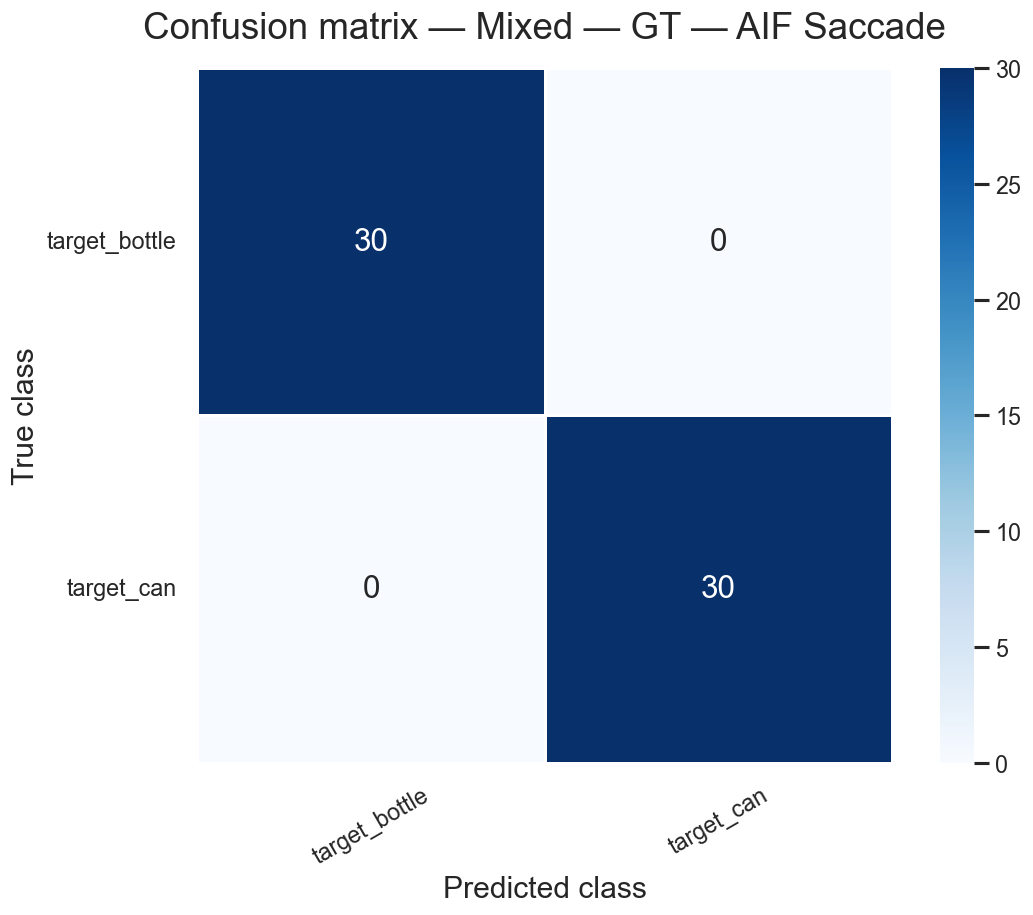

Saved figure: figures_eval_comparison/normalized_confusion_matrix___mixed___gt___aif_saccade.png


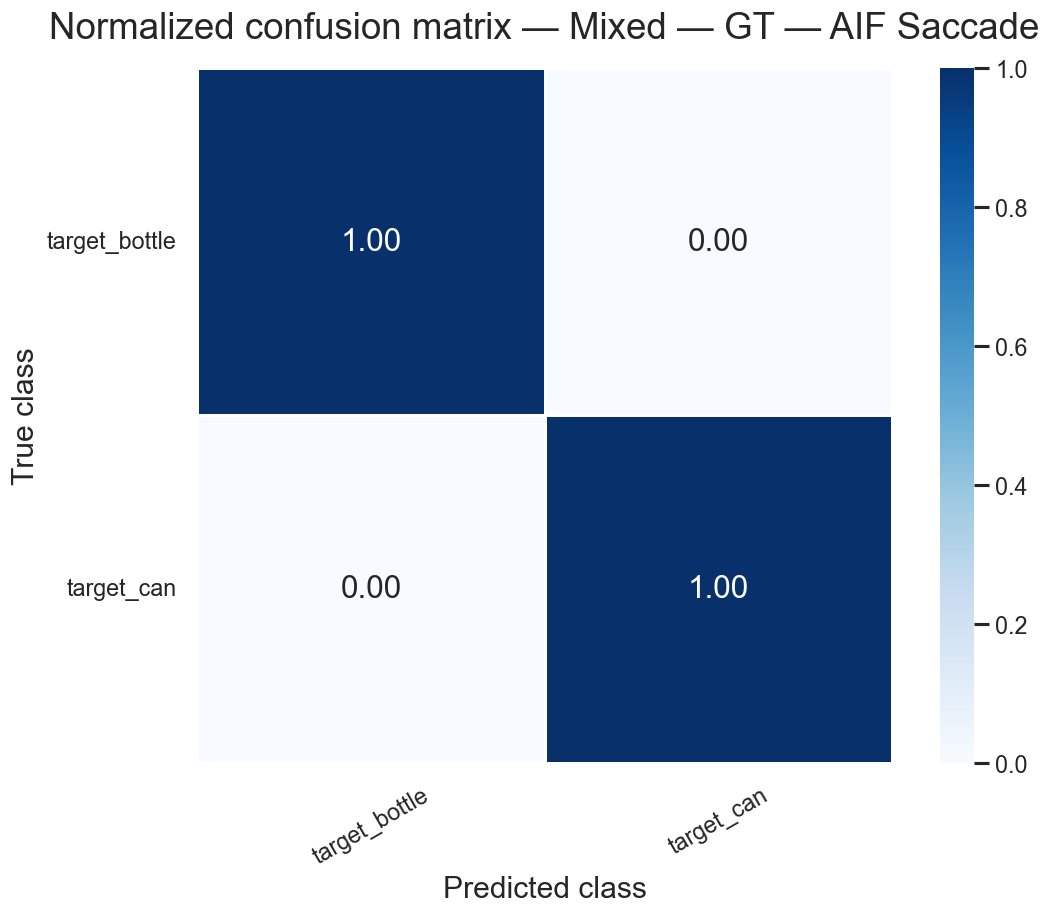

Saved figure: figures_eval_comparison/confusion_matrix___mixed___yolo___aif_saccade.png


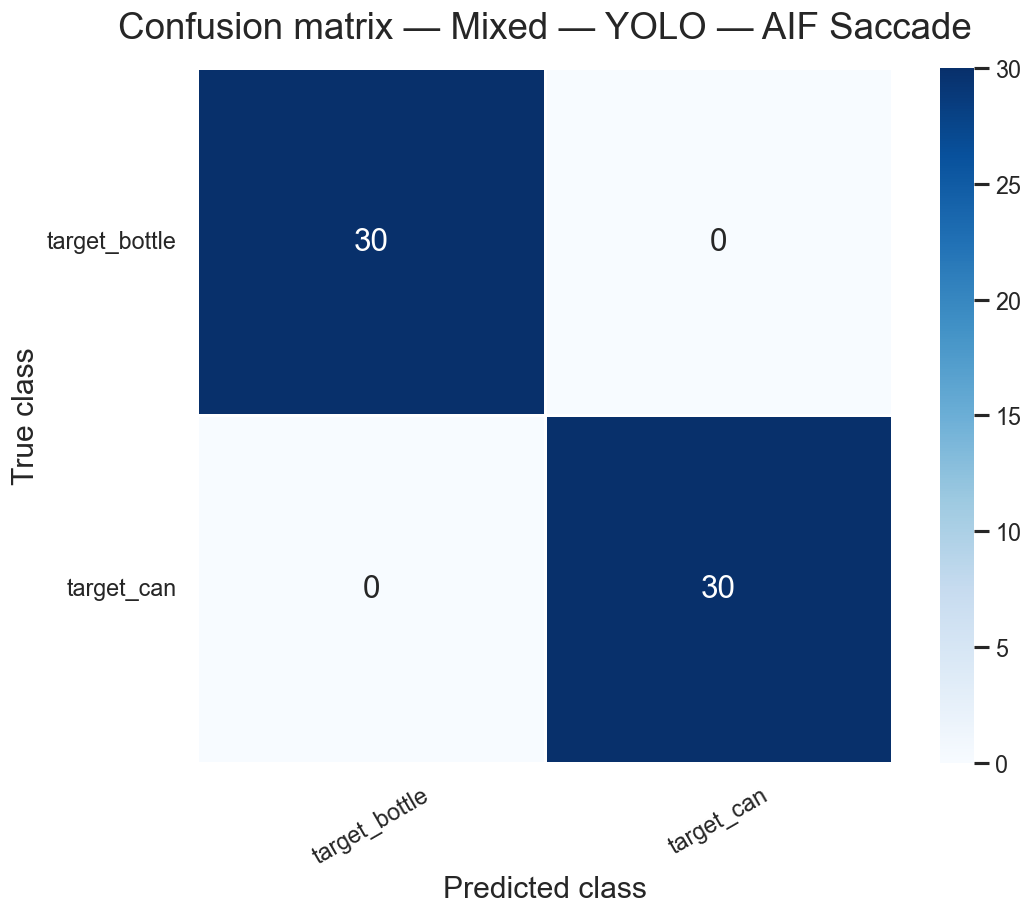

Saved figure: figures_eval_comparison/normalized_confusion_matrix___mixed___yolo___aif_saccade.png


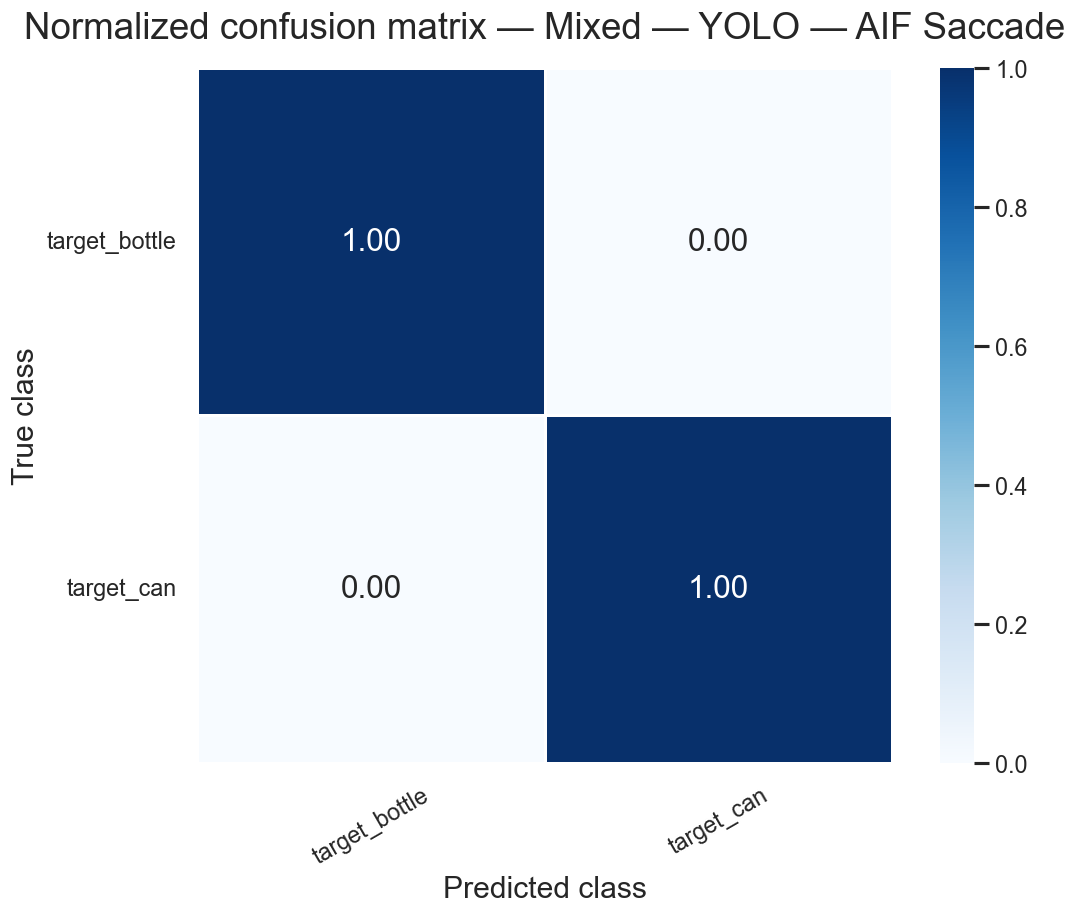

In [10]:
def aggregate_confusion_matrices(df, dataset=None, detector=None, policy=None):
    """
    Aggregates nested confusion_matrix dictionaries across all matching runs.

    Expected shape per run:
    {
        "target_bottle": {"target_bottle": 3, "target_can": 0},
        "target_can": {"target_can": 3}
    }
    """
    subset = df.copy()

    if dataset is not None:
        subset = subset[subset["dataset"] == dataset]
    if detector is not None:
        subset = subset[subset["detector"] == detector]
    if policy is not None:
        subset = subset[subset["policy"] == policy]

    matrices = subset["confusion_matrix"].dropna().tolist()
    matrices = [m for m in matrices if isinstance(m, dict)]

    if not matrices:
        return pd.DataFrame()

    true_labels = sorted({true for m in matrices for true in m.keys()})
    pred_labels = sorted({pred for m in matrices for preds in m.values() for pred in preds.keys()})
    labels = sorted(set(true_labels) | set(pred_labels))

    cm = pd.DataFrame(0, index=labels, columns=labels, dtype=float)

    for m in matrices:
        for true_label, preds in m.items():
            for pred_label, count in preds.items():
                cm.loc[true_label, pred_label] += count

    return cm


def plot_confusion_matrix(cm, title, normalize=False):
    if cm.empty:
        print(f"Skipping confusion matrix: {title} has no data.")
        return

    plot_cm = cm.copy()

    if normalize:
        row_sums = plot_cm.sum(axis=1).replace(0, np.nan)
        plot_cm = plot_cm.div(row_sums, axis=0)

    fig, ax = plt.subplots(figsize=(10, 8))

    fmt = ".2f" if normalize else ".0f"
    sns.heatmap(
        plot_cm,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        cbar=True,
        square=True,
        linewidths=0.7,
        linecolor="white",
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()

    safe_title = (
        title.lower()
        .replace(" ", "_")
        .replace("/", "_")
        .replace("—", "_")
        .replace(":", "")
    )
    save_current_figure(f"{safe_title}.png")

    plt.show()


CONFUSION_MATRIX_POLICY = "aif_saccade"

for dataset in dataset_order:
    for detector in detector_order:
        cm = aggregate_confusion_matrices(
            runs_df,
            dataset=dataset,
            detector=detector,
            policy=CONFUSION_MATRIX_POLICY,
        )

        if cm.empty:
            continue

        policy_label = pretty_policy_name(CONFUSION_MATRIX_POLICY)

        title = f"Confusion matrix — {dataset} — {detector} — {policy_label}"
        plot_confusion_matrix(cm, title, normalize=False)

        title_norm = f"Normalized confusion matrix — {dataset} — {detector} — {policy_label}"
        plot_confusion_matrix(cm, title_norm, normalize=True)

In [11]:
display(Markdown("## Sanity checks"))

# 1. Missing pairings: useful to catch missing GT/YOLO files for a policy.
coverage_table = (
    runs_df
    .groupby(["dataset", "policy_label", "detector"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
    .pivot_table(
        index=["dataset", "policy_label"],
        columns="detector",
        values="num_runs",
        observed=True,
    )
)

display(Markdown("### Number of runs available for each comparison cell"))
display(coverage_table)

# 2. Warnings for very small sample sizes.
small_n = (
    runs_df
    .groupby(["dataset", "detector", "policy_label"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
    .query("num_runs < 30")
)

if len(small_n) > 0:
    display(Markdown(
        "### Note on sample size\n"
        "Some experiment groups have fewer than 30 runs. "
        "Bar heights are still valid sample means, but the uncertainty bands can be noisy."
    ))
    display(small_n)

# 3. Classification coverage.
class_rows = runs_df[runs_df["overall_claim_precision"].notna()]
if len(class_rows) == 0:
    display(Markdown("### Classification metrics\nNo per-run classification metrics were found."))
else:
    display(Markdown("### Classification metrics present for:"))
    display(
        class_rows
        .groupby(["dataset", "detector", "policy_label"], observed=True)
        .size()
        .rename("num_runs_with_classification")
        .reset_index()
    )

## Sanity checks

### Number of runs available for each comparison cell

detector                           GT  YOLO
dataset      policy_label                  
Bottles only AIF Saccade         10.0  10.0
             Pseudo Random       10.0  10.0
             Wall Following      10.0  10.0
             Spiral              10.0  10.0
             Rotate and Measure  10.0  10.0
Mixed        AIF Saccade         10.0  10.0
             Pseudo Random       10.0  10.0
             Wall Following      10.0  10.0
             Spiral              10.0  10.0
             Rotate and Measure  10.0  10.0

### Note on sample size
Some experiment groups have fewer than 30 runs. Bar heights are still valid sample means, but the uncertainty bands can be noisy.

,dataset,detector,policy_label,num_runs
0,Bottles only,GT,AIF Saccade,10
1,Bottles only,GT,Pseudo Random,10
2,Bottles only,GT,Wall Following,10
3,Bottles only,GT,Spiral,10
4,Bottles only,GT,Rotate and Measure,10
5,Bottles only,YOLO,AIF Saccade,10
6,Bottles only,YOLO,Pseudo Random,10
7,Bottles only,YOLO,Wall Following,10
8,Bottles only,YOLO,Spiral,10
9,Bottles only,YOLO,Rotate and Measure,10


### Classification metrics present for:

,dataset,detector,policy_label,num_runs_with_classification
0,Mixed,GT,AIF Saccade,10
1,Mixed,GT,Pseudo Random,10
2,Mixed,GT,Wall Following,10
3,Mixed,GT,Spiral,10
4,Mixed,GT,Rotate and Measure,10
5,Mixed,YOLO,AIF Saccade,10
6,Mixed,YOLO,Pseudo Random,10
7,Mixed,YOLO,Wall Following,10
8,Mixed,YOLO,Spiral,10
9,Mixed,YOLO,Rotate and Measure,10
